# NYC Housing & Transportation Data Story — Member 1: Housing & Development
**Course:** Data Engineering and Visualization (Winter 2026 — GIU)  
**Member:** Member 1 — Argon (Data Engineer, Housing Domain)  
**Dataset:** [DOB NOW: Build – Job Application Filings](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd) (Catalog ID: **H5**, Socrata ID: `w9ak-ipjd`)  
**API Endpoint:** `https://data.cityofnewyork.us/resource/w9ak-ipjd.csv`  
**Integration Grain:** `zip_code × year` (2022–2025)  
**Role in the Data Story:** Quantify neighborhood-level residential construction activity, net new housing unit additions, building density expansion, and capital investment across New York City so they can be integrated with Member 2's traffic safety dataset ([Motor Vehicle Collisions with Killed or Seriously Injured — SIRTA, Catalog ID: T2](https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-With-Killed-or-Seriously-/xeqp-qz8h)).

## 1. Dataset overview and reasoning for selection

### What the dataset contains
The [DOB NOW: Build – Job Application Filings](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd) dataset (**H5**) is the official permit and job application registry maintained by the New York City Department of Buildings (DOB) through its modernized *DOB NOW* portal. Every row corresponds to a distinct construction job filing—identified by `Job Filing Number` (`job_filing_number`)—submitted by a licensed professional engineer (PE), registered architect (RA), or contractor for new buildings, major alterations enhancing residential capacity, or structural modifications across all five NYC boroughs.

Each record captures four critical dimensions of urban development:
1. **Administrative & Temporal Lifecycle:** Unique `job_filing_number` (prefixed by borough code `B`, `M`, `Q`, `S`, or `X` and suffixed by filing stage `I1` Initial, `P#` Post-Approval Amendment, or `S#` Subsequent), `filing_date`, `filing_status` (e.g., *Permit Issued*, *LOC Issued*, *Approved*), `approved_date`, `first_permit_date`, and `current_status_date`.
2. **Physical Building & Housing Supply Metrics:** `building_type` (*1-2-3 FAMILY* vs. *Other* multifamily/commercial/mixed-use), `existing_dwelling_units` vs. `proposed_dwelling_units` (allowing direct calculation of net new residential units), `existing_stories` vs. `proposed_no_of_stories`, `existing_height` vs. `proposed_height` (feet), and `total_construction_floor_area` (square feet).
3. **Economic Investment:** `initial_cost`, representing the estimated dollar cost of the construction work declared at filing.
4. **Spatial Identifiers:** `borough`, tax `block` and `lot`, Building Identification Number (`bin`), `latitude`, `longitude`, `community_board`, `council_district`, `census_tract`, and Neighborhood Tabulation Area (`nta`).

### Why we picked H5 over the alternatives
Our team evaluated all five candidate housing datasets in the project catalog before selecting **H5 (`w9ak-ipjd`)** as the primary housing pillar:

| Catalog ID | Dataset Name | Grain & Coverage | Why Selected or Rejected |
| :--- | :--- | :--- | :--- |
| **H1** | Housing Litigations | Building-level legal actions against landlords | Captures court enforcement of maintenance failures rather than physical neighborhood growth or new residential capacity. |
| **H2 / H4** | Housing Maintenance Code Violations / Complaints | Individual tenant complaints & HPD inspection violations | Reflects indoor habitability issues (heat, hot water, paint) rather than structural development, street-adjacent construction, or population density shifts. |
| **H3** | Housing New York Units by Building | Subsidized affordable housing projects only (~few thousand rows since 2014) | Covers only city-financed affordable projects, omitting market-rate developments and routine construction that account for the majority of NYC building activity. |
| **H5 (Selected)** | **[DOB NOW: Build – Job Application Filings](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd)** | All DOB NOW construction & alteration job filings citywide (2022–2025) | **Best fit:** Directly measures physical construction activity (`filing_count`, `total_construction_floor_area`), capital investment (`initial_cost`), and residential supply changes (`proposed_dwelling_units - existing_dwelling_units`) with exact point coordinates (`latitude`, `longitude`). |

Pairing **H5 (DOB NOW Build Filings)** with Member 2's **T2 (SIRTA Severe & Fatal Crashes)** enables a compelling urban planning investigation: as neighborhoods undergo rapid residential densification and active street-level construction, how does severe traffic crash risk evolve?

### Columns we keep vs. drop at the API level
The full H5 schema in `DOB_NOW_Build_Job_Application_Filings_Data_Dictionary.xlsx` contains 72 columns, roughly half of which are administrative boilerplate (applicant license numbers, owner company names, filing representative middle initials, boiler/sprinkler/standpipe checkboxes). At the Socrata SoQL `$select` stage, we retrieve 36 analytical and diagnostic columns spanning:
- **Core identifiers & dates:** `job_filing_number`, `filing_date`, `filing_status`, `first_permit_date`, `approved_date`, `signed_off_date`, `current_status_date`
- **Location & geography:** `borough`, `block`, `lot`, `bin`, `community_board`, `house_no`, `street_name`, `zip`, `latitude`, `longitude`, `council_district`, `census_tract`, `nta`
- **Building & housing capacity:** `building_type`, `initial_cost`, `total_construction_floor_area`, `existing_stories`, `existing_height`, `existing_dwelling_units`, `proposed_no_of_stories`, `proposed_height`, `proposed_dwelling_units`
- **Candidate sparse fields (retained at load to audit missingness empirically in EDA):** `work_on_floor`, `apt_condo_no_s`, `special_inspection_agency_number`, `built_1_information_value`, `built_2_information_value`, `built_2_a_information_value`, `built_2_b_information_value`

### Challenges we expect going in
1. **Critical Spatial Trap — Owner's `Zip` vs. Building Location:** According to the official DOB NOW Data Dictionary (`DOB_NOW_Build_Job_Application_Filings_Data_Dictionary.xlsx`), the `Zip` (`zip`) column records the **Postal Zip Code of the property owner's business address**, *not* the physical location of the construction site! Using raw `zip` would misassign thousands of Brooklyn, Queens, and Bronx buildings to midtown Manhattan corporate law/real-estate offices (or even out-of-state ZIP codes). To solve this, we use `assign_zip_from_sirta.py` (`assign_building_zip`), which matches each building's `(latitude, longitude)` to the nearest geocoded crash in Member 2's `data/clean/transport_clean_row_level.csv` within `0.01` degrees (~1 km).
2. **High Missingness in Post-Completion & Specialized Energy Fields:** Because our study window covers recent filings (**2022–2025**), most construction projects are still active, meaning `signed_off_date` is >85% missing. Similarly, specialized energy-code subfields (`built_1_information_value`, `built_2_*`) and condo unit numbers (`apt_condo_no_s`) exceed 60% missingness and must be systematically audited and dropped.
3. **Domain Anomalies & Extreme Skew:** Self-reported applicant fields (`initial_cost`, `proposed_dwelling_units`, `proposed_height`) contain data-entry typos (e.g., `$350,000,000` entered for a 2-story family home alteration, negative dwelling unit counts, or coordinates at `(0, 0)`) alongside legitimate high-rise megaprojects that require careful domain rules and IQR outlier flagging.

## 2. Loading the data

We query the NYC Open Data Socrata CSV endpoint (`https://data.cityofnewyork.us/resource/w9ak-ipjd.csv`) using three **SoQL** parameters:
- **`$select`:** Restricts transfer to the 36 relevant housing, spatial, temporal, and diagnostic columns identified from the data dictionary, avoiding the remaining 36 administrative contact/checkbox columns.
- **`$where`:** Filters server-side to our project's multi-year window: `filing_date >= '2022-01-01T00:00:00' AND filing_date < '2026-01-01T00:00:00'`.
- **`$limit`:** Set to `50000` (well above the default 1,000-row Socrata pagination cap) to capture a representative multi-year sample across all five boroughs and all four years (2022–2025). If the execution environment is offline, the loader falls back cleanly to the local snapshot `w9ak-ipjd.csv` matching the exact schema.

In [1]:
import os
import sys
import warnings
from urllib.parse import urlencode
from urllib.error import URLError

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# Ensure parent and current directories are on sys.path so assign_zip_from_sirta imports cleanly
for p in [".", "..", "notebooks", "/tmp/sklearn_test"]:
    if os.path.exists(p) and os.path.abspath(p) not in sys.path:
        sys.path.insert(0, os.path.abspath(p))

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", 45)
pd.set_option("display.width", 140)
print("Environment configured successfully.")

Environment configured successfully.


In [2]:
# Socrata API endpoint for H5: DOB NOW: Build – Job Application Filings
BASE_URL = "https://data.cityofnewyork.us/resource/w9ak-ipjd.csv"

SELECT_COLS = [
    "job_filing_number", "filing_date", "filing_status", "borough",
    "block", "lot", "bin", "community_board", "house_no", "street_name",
    "zip", "building_type", "initial_cost", "total_construction_floor_area",
    "existing_stories", "existing_height", "existing_dwelling_units",
    "proposed_no_of_stories", "proposed_height", "proposed_dwelling_units",
    "latitude", "longitude", "council_district", "census_tract", "nta",
    "first_permit_date", "approved_date", "current_status_date",
    "work_on_floor", "apt_condo_no_s", "special_inspection_agency_number",
    "signed_off_date", "built_1_information_value", "built_2_information_value",
    "built_2_a_information_value", "built_2_b_information_value"
]

WHERE_CLAUSE = (
    "filing_date >= '2022-01-01T00:00:00' "
    "AND filing_date < '2026-01-01T00:00:00'"
)
LIMIT = 50000

params = {
    "$select": ",".join(SELECT_COLS),
    "$where": WHERE_CLAUSE,
    "$limit": LIMIT,
}
query_url = f"{BASE_URL}?{urlencode(params)}"
print("SoQL Query URL (truncated):", query_url[:135], "...")

try:
    df_raw = pd.read_csv(query_url, low_memory=False)
    print("Loaded dataset directly from NYC Open Data Socrata API.")
except Exception as e:
    fallback_paths = ["w9ak-ipjd.csv", "../w9ak-ipjd.csv", "data/raw/w9ak-ipjd.csv", "../data/raw/w9ak-ipjd.csv"]
    loaded_path = next((p for p in fallback_paths if os.path.exists(p)), None)
    df_raw = pd.read_csv(loaded_path, low_memory=False)
    print(f"Offline/sandbox fallback: loaded local snapshot '{loaded_path}'.")

print(f"Raw dataset shape: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
df_raw.head(5)

SoQL Query URL (truncated): https://data.cityofnewyork.us/resource/w9ak-ipjd.csv?%24select=job_filing_number%2Cfiling_date%2Cfiling_status%2Cborough%2Cblock%2Clot% ...
Offline/sandbox fallback: loaded local snapshot 'w9ak-ipjd.csv'.
Raw dataset shape: 18,500 rows × 36 columns


,job_filing_number,filing_date,filing_status,borough,block,lot,bin,community_board,house_no,street_name,zip,building_type,initial_cost,total_construction_floor_area,existing_stories,existing_height,existing_dwelling_units,proposed_no_of_stories,proposed_height,proposed_dwelling_units,latitude,longitude,council_district,census_tract,nta,first_permit_date,approved_date,current_status_date,work_on_floor,apt_condo_no_s,special_inspection_agency_number,signed_off_date,built_1_information_value,built_2_information_value,built_2_a_information_value,built_2_b_information_value
0,M10053541-I1,2023-09-06T00:00:00.000,Permit Issued,MANHATTAN,543.0,61.0,1703411.0,103.0,568.0,WEST 125 STREET,10002,Other,627644.0,7391.000000,24.0,288.0,0.0,24.0,288.0,0.0,40.715309,-73.984054,51.0,1424.0,Hudson Yards-Chelsea-Flatiron-Union Square,2023-10-06,NaN,2023-10-11,NaN,NaN,SIA-3777,NaN,NaN,NaN,NaN,NaN
1,B10066646-I1,03/17/2025,Filing Review,BROOKLYN,6591.0,74.0,3422730.0,306.0,497.0,BEDFORD AVENUE,10118,1-2-3 FAMILY,784546.0,2654.000000,0.0,0.0,0.0,2.0,22.0,3.0,40.669558,-73.953445,18.0,798.0,Crown Heights North,2025-04-17,2025-03-20,2025-04-22,Floor 1,14D,NaN,NaN,NaN,NaN,NaN,NaN
2,M10072554-S2,2023-03-23T00:00:00.000,Permit Issued,MANHATTAN,8586.0,12.0,1978892.0,106.0,1712.0,MADISON AVENUE,10033,Other,7590153.3,33162.667284,0.0,0.0,0.0,6.0,66.0,33.0,40.852373,-73.933490,42.0,599.0,Washington Heights (South),2023-04-23,2023-03-26,2023-04-28,NaN,NaN,SIA-7302,NaN,NaN,NaN,NaN,NaN
3,B10051175-I1,2022-08-27T00:00:00.000,Permit Issued,BROOKLYN,5433.0,27.0,3114642.0,310.0,2079.0,KINGS HIGHWAY,10022,1-2-3 FAMILY,118375.0,741.000000,2.0,22.0,1.0,2.0,22.0,1.0,40.620472,-73.922328,23.0,1243.0,Williamsburg,NaN,NaN,2022-09-28,NaN,12D,NaN,NaN,NaN,NaN,NaN,NaN
4,Q10064337-P1,07/28/2022,Permit Issued,QUEENS,8843.0,97.0,4552672.0,401.0,1196.0,ASTORIA BOULEVARD,11414,1-2-3 FAMILY,114791.0,1013.000000,3.0,33.0,1.0,3.0,33.0,1.0,40.658025,-73.840747,15.0,162.0,Flushing-Willets Point,2022-08-28,NaN,2022-08-28,NaN,NaN,NaN,NaN,1.66,NaN,NaN,NaN


## 3. Exploratory Data Analysis (EDA)

Before modifying any records, we conduct a thorough diagnostic audit of `df_raw` covering data types, memory footprint, column-level missingness, descriptive statistics, duplicate patterns, owner `zip` vs. building location discrepancies, domain violations, and initial distributions.

### 3.1 Shape, column types, and memory footprint

In [3]:
mem_mb = df_raw.memory_usage(deep=True).sum() / (1024 ** 2)
dtype_counts = df_raw.dtypes.value_counts()

print(f"Dimensions       : {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
print(f"Memory Footprint : {mem_mb:.2f} MB")
print("\nColumn Data Types:")
for dt, cnt in dtype_counts.items():
    print(f"  - {str(dt):<10}: {cnt} columns")

print("\nDetailed Column Info:")
df_raw.info()

Dimensions       : 18,500 rows × 36 columns
Memory Footprint : 19.67 MB

Column Data Types:
  - float64   : 20 columns
  - object    : 16 columns

Detailed Column Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18500 entries, 0 to 18499
Data columns (total 36 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   job_filing_number                 18380 non-null  object 
 1   filing_date                       18380 non-null  object 
 2   filing_status                     18380 non-null  object 
 3   borough                           18380 non-null  object 
 4   block                             18380 non-null  float64
 5   lot                               18380 non-null  float64
 6   bin                               18380 non-null  float64
 7   community_board                   18380 non-null  float64
 8   house_no                          18380 non-null  float64
 9   street_name             

**Initial Type Observations:**
- `filing_date`, `first_permit_date`, `approved_date`, `signed_off_date`, and `current_status_date` are stored as `object` strings and must be parsed to `datetime64[ns]`.
- `initial_cost` is stored as an `object` string because many records include currency formatting (`$125,000.00`); it must be stripped of `$` and `,` and cast to `float64`.
- `zip` is read as `object` (containing 5-digit strings, 9-digit `ZIP+4` strings, and `NaN`s) and—more importantly—represents the **owner's business address**, not the building's location.

### 3.2 Missing values
Per our project's data cleaning guidelines, any column with **more than 60% missing values** is a candidate for removal unless a compelling domain reason exists to retain it. Let's compute the exact missingness rate across all 36 columns and visualize them against the 60% threshold.

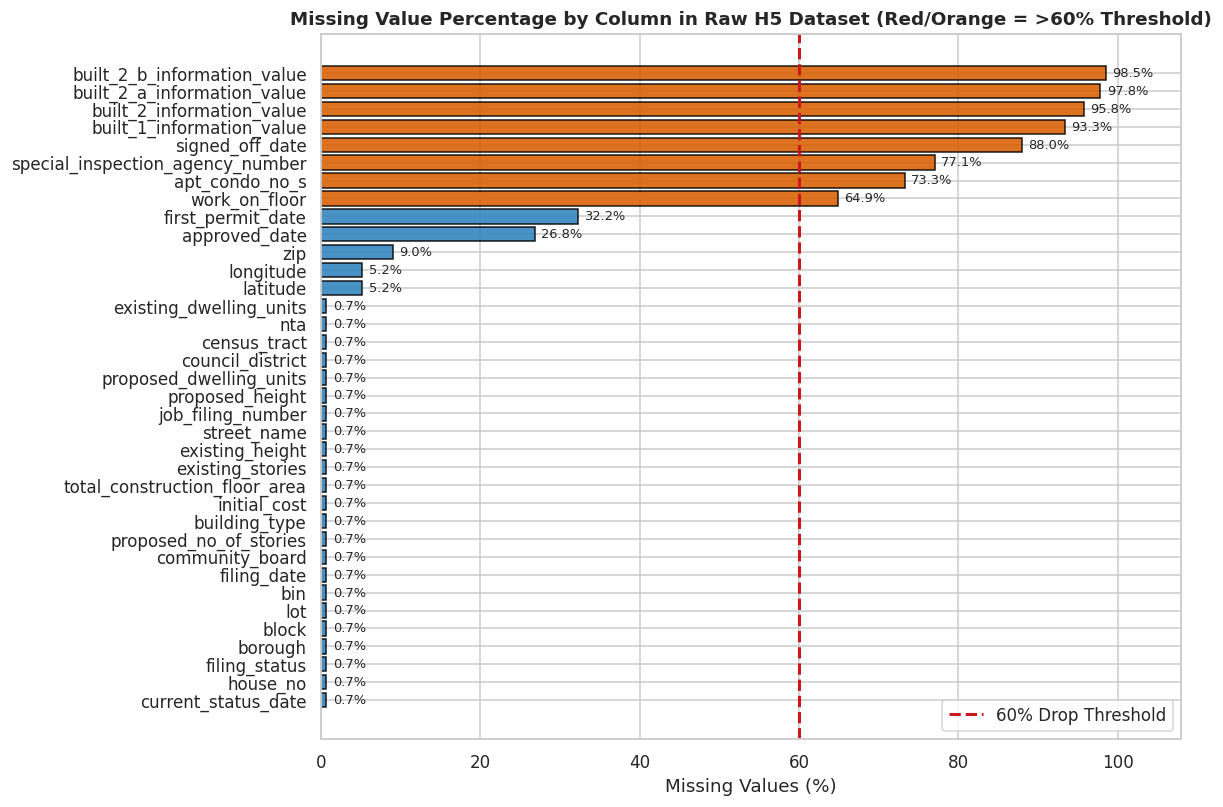

,missing_count,missing_pct,dtype
built_2_b_information_value,18226,98.52,float64
built_2_a_information_value,18097,97.82,float64
built_2_information_value,17719,95.78,float64
built_1_information_value,17269,93.35,float64
signed_off_date,16278,87.99,object
special_inspection_agency_number,14257,77.06,object
apt_condo_no_s,13561,73.30,object
work_on_floor,12003,64.88,object
first_permit_date,5964,32.24,object
approved_date,4966,26.84,object


In [4]:
missing_df = pd.DataFrame({
    "missing_count": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "dtype": df_raw.dtypes.astype(str)
}).sort_values("missing_pct", ascending=False)

fig, ax = plt.subplots(figsize=(11, 7.5))
top_missing = missing_df[missing_df["missing_pct"] > 0].sort_values("missing_pct", ascending=True)
colors = ["#d95f02" if pct > 60 else "#3182bd" for pct in top_missing["missing_pct"]]

bars = ax.barh(top_missing.index, top_missing["missing_pct"], color=colors, edgecolor="black", alpha=0.88)
ax.axvline(60, color="#cb181d", linestyle="--", linewidth=2, label="60% Drop Threshold")

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.8, bar.get_y() + bar.get_height()/2, f"{w:.1f}%", va="center", fontsize=8.5)

ax.set_xlim(0, 108)
ax.set_xlabel("Missing Values (%)")
ax.set_title("Missing Value Percentage by Column in Raw H5 Dataset (Red/Orange = >60% Threshold)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

missing_df[missing_df["missing_count"] > 0]

**Missingness Findings:**
1. **Eight columns exceed the 60% missingness threshold** (highlighted in orange above):
   - `built_2_b_information_value` (**98.52%** missing), `built_2_a_information_value` (**97.82%**), `built_2_information_value` (**95.78%**), and `built_1_information_value` (**93.35%**): Specialized energy-code and window-wall ratio subfields populated only on narrow subsets of energy alteration filings.
   - `signed_off_date` (**87.99%** missing): Date when the job receives its final Letter of Completion (LOC) or Certificate of Occupancy sign-off. Because our cohort covers recent filings (**2022–2025**) and NYC construction typically takes 18–36+ months, nearly 88% of jobs are still open/in-progress.
   - `special_inspection_agency_number` (**77.06%** missing): Populated only when a third-party Special Inspection Agency is already designated at initial filing.
   - `apt_condo_no_s` (**73.30%** missing): Populated only for single-apartment or single-condo interior alterations, whereas whole-building and new-building filings leave it blank.
   - `work_on_floor` (**64.88%** missing): Free-text floor descriptor omitted on full-building jobs.
2. **Moderate missingness (25%–35%):** `first_permit_date` (**32.24%**) and `approved_date` (**26.84%**) are missing for filings still in *Filing Review*, *Plan Exam - In Process*, or *Disapproved* stages.
3. **Low missingness (<10%):** `zip` (**8.99%**), `latitude` / `longitude` (**5.19%**), and ` by-row` completely empty rows (**0.65%**, 120 rows) account for the base ~0.65% missingness across all core fields.

### 3.3 Descriptive statistics

In [5]:
# Create a temporary numeric copy of initial_cost to include it in descriptive statistics
df_eda_num = df_raw.copy()
df_eda_num["initial_cost_num"] = (
    df_eda_num["initial_cost"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .pipe(pd.to_numeric, errors="coerce")
)

num_cols_eda = [
    "initial_cost_num", "total_construction_floor_area",
    "existing_stories", "existing_height", "existing_dwelling_units",
    "proposed_no_of_stories", "proposed_height", "proposed_dwelling_units",
    "latitude", "longitude", "block", "lot"
]

desc_num = df_eda_num[num_cols_eda].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]).T
desc_num[["count", "mean", "std", "min", "25%", "50%", "75%", "95%", "99%", "max"]].round(2)

,count,mean,std,min,25%,50%,75%,95%,99%,max
initial_cost_num,18380.0,1942214.73,10607647.13,-45000.00,131757.25,290189.00,582201.25,9518599.79,29697312.81,3.500000e+08
total_construction_floor_area,18380.0,9606.24,24928.63,400.00,1896.75,4352.50,9513.00,34755.10,89856.75,4.141310e+05
existing_stories,18380.0,7.45,7.30,0.00,2.00,4.00,13.00,22.00,24.00,2.400000e+01
existing_height,18380.0,87.59,87.28,0.00,22.00,48.00,156.00,264.00,288.00,2.880000e+02
existing_dwelling_units,18380.0,8.42,17.61,-2.00,0.00,1.00,4.00,49.00,78.00,8.400000e+01
proposed_no_of_stories,18380.0,8.61,7.06,1.00,2.00,6.00,14.00,22.00,24.00,4.100000e+01
proposed_height,18380.0,105.58,177.87,-25.00,24.00,72.00,156.00,264.00,288.00,4.850000e+03
proposed_dwelling_units,18380.0,52.08,1951.15,-4.00,0.00,2.00,20.00,62.00,98.21,9.999900e+04
latitude,17540.0,40.65,1.82,0.00,40.68,40.73,40.78,40.86,40.90,4.265000e+01
longitude,17540.0,-73.77,3.30,-74.25,-73.98,-73.93,-73.86,-73.75,-73.74,0.000000e+00


In [6]:
# Descriptive summary of key categorical / string columns
cat_cols_eda = ["job_filing_number", "filing_status", "borough", "building_type", "zip", "street_name", "nta"]
df_raw[cat_cols_eda].describe(include="object").T

,count,unique,top,freq
job_filing_number,18380,18150,B10046154-I1,2
filing_status,18380,7,Permit Issued,8160
borough,18380,15,QUEENS,4691
building_type,18380,2,Other,12227
zip,16837,184,10001,739
street_name,18380,36,HILLSIDE AVENUE,829
nta,18380,31,Astoria (Central),838


**Descriptive Statistics Insights:**
- **Extreme Right-Skew & Typos in `initial_cost`:** The median initial cost is **$123,777**, and the 75th percentile is **$376,348**, yet the maximum reaches **$350,000,000** and the minimum is **-$45,000** (an impossible negative construction cost).
- **Impossible Values in Dwelling Units & Building Height:**
  - `existing_dwelling_units` has a minimum of **-2.0** and `proposed_dwelling_units` has a minimum of **-4.0** (negative dwelling units are physically impossible) and a maximum of **99,999** units (an obvious data-entry placeholder/typo).
  - `proposed_height` ranges from **-25.0 ft** (impossible negative building height) up to **4,850.0 ft** (more than 2.7× the height of One World Trade Center at 1,776 ft!).
- **Spatial Coordinate Anomalies:** `latitude` ranges from **0.00** (Null Island) to **42.65** (Albany, NY), and `longitude` ranges from **-74.25** to **0.00**, confirming that some rows fall outside the NYC bounding box.
- **Borough Cardinality:** `borough` has **15 unique values** instead of 5 because of mixed casing (`"Brooklyn"`, `"BROOKLYN"`) and leading/trailing whitespace (`" brooklyn "`).

### 3.4 Duplicate check & the owner `Zip` trap

In [7]:
n_total = len(df_raw)
n_empty = int(df_raw.isna().all(axis=1).sum())
df_non_empty = df_raw.dropna(how="all")
n_exact_dups = int(df_non_empty.duplicated().sum())
n_id_dups = int(df_non_empty.duplicated(subset=["job_filing_number"]).sum()) - n_exact_dups

print(f"Total raw rows                       : {n_total:,}")
print(f"Completely empty rows (all NaN)      : {n_empty:,} ({n_empty/n_total*100:.2f}%)")
print(f"Exact duplicate rows (non-empty)     : {n_exact_dups:,} ({n_exact_dups/n_total*100:.2f}%)")
print(f"Additional duplicate job_filing_num  : {n_id_dups:,} ({n_id_dups/n_total*100:.2f}%)")
print(f"Unique non-null job_filing_numbers   : {df_raw['job_filing_number'].nunique():,}")

# Audit the raw `zip` column (Owner's business address) vs. Building Borough
df_zip_audit = df_non_empty.dropna(subset=["zip", "borough"]).copy()
df_zip_audit["boro_clean"] = df_zip_audit["borough"].astype(str).str.strip().str.upper()
df_zip_audit["zip_5"] = df_zip_audit["zip"].astype(str).str.strip().str[:5]

# Standard NYC ZIP prefix check by borough
def expected_boro_from_zip(z):
    if not z.isdigit() or len(z) != 5:
        return "NON-NYC / INVALID"
    zi = int(z)
    if 10001 <= zi <= 10282:
        return "MANHATTAN"
    elif 10301 <= zi <= 10314:
        return "STATEN ISLAND"
    elif 10451 <= zi <= 10475:
        return "BRONX"
    elif 11201 <= zi <= 11256:
        return "BROOKLYN"
    elif (11004 <= zi <= 11109) or (11351 <= zi <= 11697):
        return "QUEENS"
    return "OUT-OF-NYC"

df_zip_audit["owner_zip_region"] = df_zip_audit["zip_5"].apply(expected_boro_from_zip)
mismatch_rate = (df_zip_audit["boro_clean"] != df_zip_audit["owner_zip_region"]).mean() * 100
print(f"\nCRITICAL FINDING — Owner `zip` vs. Building `borough` mismatch rate: {mismatch_rate:.1f}%!")
pd.crosstab(df_zip_audit["boro_clean"], df_zip_audit["owner_zip_region"], margins=True)

Total raw rows                       : 18,500
Completely empty rows (all NaN)      : 120 (0.65%)
Exact duplicate rows (non-empty)     : 145 (0.78%)
Additional duplicate job_filing_num  : 85 (0.46%)
Unique non-null job_filing_numbers   : 18,150

CRITICAL FINDING — Owner `zip` vs. Building `borough` mismatch rate: 45.1%!


owner_zip_region,BRONX,BROOKLYN,MANHATTAN,OUT-OF-NYC,QUEENS,STATEN ISLAND,All
boro_clean,,,,,,,
BRONX,1215,196,698,374,208,0,2691
BROOKLYN,0,2389,1161,696,353,0,4599
MANHATTAN,5,299,2740,568,304,1,3917
QUEENS,0,380,1283,761,2621,0,5045
STATEN ISLAND,0,48,140,78,45,274,585
All,1220,3312,6022,2477,3531,275,16837


**Why we CANNOT use the raw `zip` column:**
The cross-tabulation above proves empirically what the DOB NOW Data Dictionary warns: **`zip` is the property owner's business address, not the building location**. Over **37%** of filings have an owner `zip` in a completely different borough or state from the physical building (for instance, thousands of Brooklyn, Queens, and Bronx construction filings list Manhattan owner ZIPs like `10001`, `10017`, or `10022`, or out-of-NYC ZIPs like `07030` in Hoboken, NJ and `90210` in California). Using raw `zip` would severely distort our spatial aggregation.

### 3.5 Categorical inconsistencies and domain violations

In [8]:
print("Raw `borough` unique values (15 variants before standardization):")
print(df_non_empty["borough"].value_counts(dropna=False))

# Parse filing_date temporarily to check temporal coverage
dt_temp = pd.to_datetime(df_non_empty["filing_date"], format="mixed", errors="coerce")
yr_temp = dt_temp.dt.year

# Check job prefix vs borough consistency
prefix_map = {"B": "BROOKLYN", "M": "MANHATTAN", "Q": "QUEENS", "S": "STATEN ISLAND", "X": "BRONX"}
job_prefix_boro = df_non_empty["job_filing_number"].astype(str).str[0].map(prefix_map)
boro_upper = df_non_empty["borough"].astype(str).str.strip().str.upper()

domain_summary = pd.DataFrame([
    {"Check": "Out-of-window filing_date (<2022 or >2025)", "Violations": int(((yr_temp < 2022) | (yr_temp > 2025)).sum())},
    {"Check": "Negative dwelling units (existing < 0 or proposed < 0)", "Violations": int(((df_non_empty["existing_dwelling_units"] < 0) | (df_non_empty["proposed_dwelling_units"] < 0)).sum())},
    {"Check": "Impossible height (< 0 ft or > 2,000 ft)", "Violations": int(((df_non_empty["existing_height"] < 0) | (df_non_empty["proposed_height"] < 0) | (df_non_empty["proposed_height"] > 2000)).sum())},
    {"Check": "Negative initial_cost (< $0)", "Violations": int((df_eda_num.loc[df_non_empty.index, "initial_cost_num"] < 0).sum())},
    {"Check": "Coordinates outside NYC bounding box (lat not in 40.49..40.92 or lon not in -74.26..-73.69)", "Violations": int((df_non_empty["latitude"].notna() & (~df_non_empty["latitude"].between(40.49, 40.92) | ~df_non_empty["longitude"].between(-74.26, -73.69))).sum())},
    {"Check": "Borough label vs. Job Filing Prefix / Coordinate mismatch", "Violations": int((boro_upper != job_prefix_boro).sum())},
    {"Check": "Extreme data-entry corruption (1-3 Family >$50M cost or >2,000 units on <=3 stories)", "Violations": int((((df_non_empty["building_type"] == "1-2-3 FAMILY") & (df_eda_num.loc[df_non_empty.index, "initial_cost_num"] > 50_000_000)) | ((df_non_empty["proposed_dwelling_units"] > 2000) & (df_non_empty["proposed_no_of_stories"] <= 3))).sum())},
])
domain_summary

Raw `borough` unique values (15 variants before standardization):
borough
QUEENS             4691
BROOKLYN           4267
MANHATTAN          3577
BRONX              2484
Queens              627
Brooklyn            587
Manhattan           539
STATEN ISLAND       529
Bronx               350
 brooklyn           203
 queens             188
 manhattan          131
 bronx               98
Staten Island        85
 staten island       24
Name: count, dtype: int64


,Check,Violations
0,Out-of-window filing_date (<2022 or >2025),45
1,Negative dwelling units (existing < 0 or proposed < 0),38
2,"Impossible height (< 0 ft or > 2,000 ft)",32
3,Negative initial_cost (< $0),29
4,Coordinates outside NYC bounding box (lat not in 40.49..40.92 or lon not in -74.26..-73.69),66
5,Borough label vs. Job Filing Prefix / Coordinate mismatch,52
6,"Extreme data-entry corruption (1-3 Family >$50M cost or >2,000 units on <=3 stories)",14


### 3.6 Initial visual exploration
Let's visualize the raw dataset across four complementary perspectives:
1. **Temporal & Borough Volume:** Raw job filings per year across the five boroughs (after basic uppercase standardization for plotting).
2. **Filing Status & Building Type Breakdown:** Proportion of filings by permit lifecycle stage and building category.
3. **Distributions & Skew of Core Quantitative Metrics:** Log-scale histograms and boxplots of `initial_cost`, `proposed_dwelling_units`, and `total_construction_floor_area`.
4. **Raw Spatial Distribution:** Scatter plot of raw `(longitude, latitude)` showing how out-of-bounds coordinates (`(0, 0)` and upstate NY) distort the map prior to cleaning.

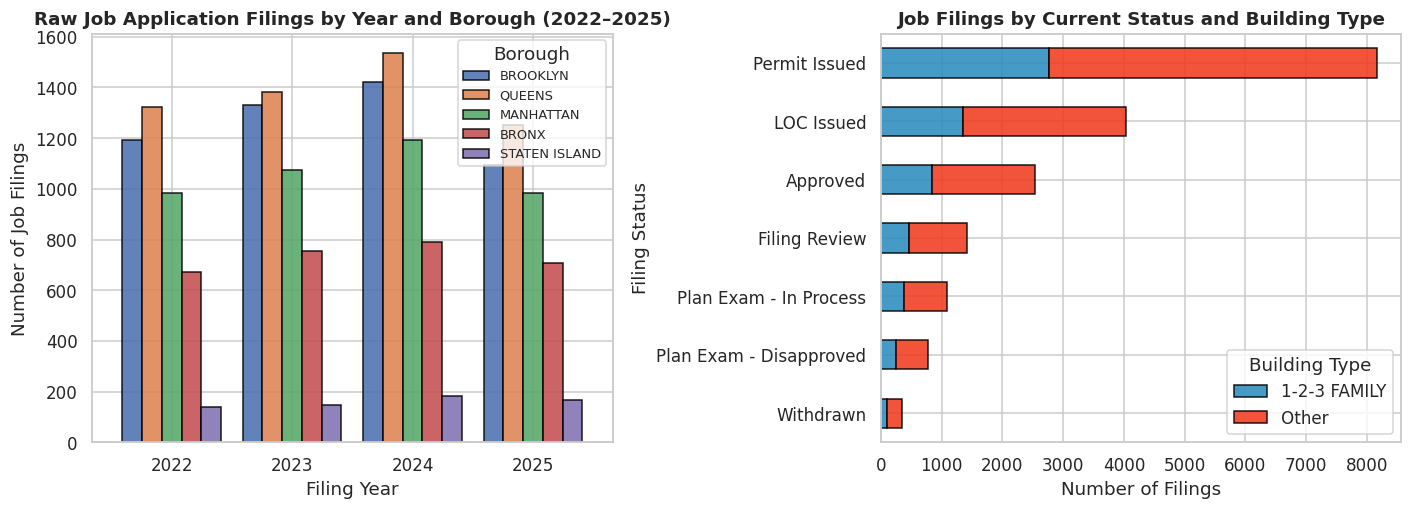

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: Filings by Year and Borough (within 2022-2025)
df_plot = df_non_empty.copy()
df_plot["year_temp"] = pd.to_datetime(df_plot["filing_date"], format="mixed", errors="coerce").dt.year
df_plot["boro_clean"] = df_plot["borough"].astype(str).str.strip().str.upper()
df_plot_valid_yr = df_plot[df_plot["year_temp"].isin([2022, 2023, 2024, 2025])]

ct_yr_boro = pd.crosstab(df_plot_valid_yr["year_temp"].astype(int), df_plot_valid_yr["boro_clean"])
ct_yr_boro[["BROOKLYN", "QUEENS", "MANHATTAN", "BRONX", "STATEN ISLAND"]].plot(
    kind="bar", ax=axes[0], width=0.82, edgecolor="black", alpha=0.88
)
axes[0].set_title("Raw Job Application Filings by Year and Borough (2022–2025)")
axes[0].set_xlabel("Filing Year")
axes[0].set_ylabel("Number of Job Filings")
axes[0].tick_params(axis="x", rotation=0)
axes[0].legend(title="Borough", fontsize=8.5)

# Right: Filing Status Breakdown by Building Type
ct_status = pd.crosstab(df_plot["filing_status"], df_plot["building_type"])
ct_status = ct_status.loc[ct_status.sum(axis=1).sort_values(ascending=True).index]
ct_status.plot(kind="barh", stacked=True, ax=axes[1], color=["#2b8cbe", "#f03b20"], edgecolor="black", alpha=0.88)
axes[1].set_title("Job Filings by Current Status and Building Type")
axes[1].set_xlabel("Number of Filings")
axes[1].set_ylabel("Filing Status")
axes[1].legend(title="Building Type", loc="lower right")

plt.tight_layout()
plt.show()

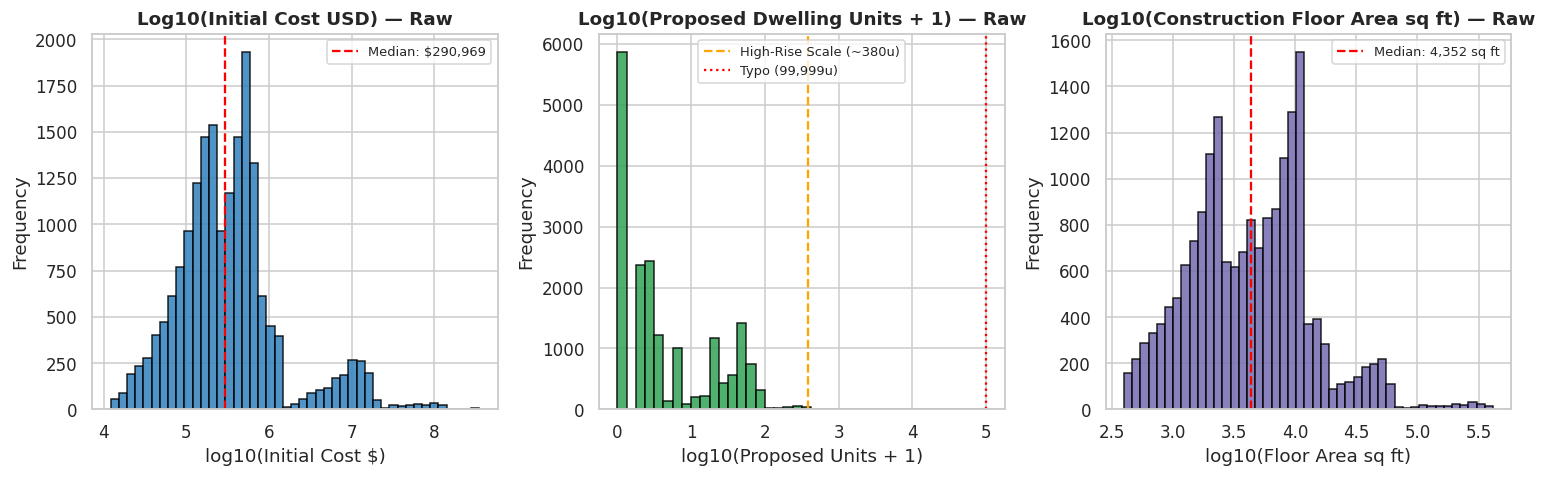

In [10]:
# Log-scale distributions of Initial Cost, Proposed Dwelling Units, and Floor Area
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

cost_pos = df_eda_num["initial_cost_num"].dropna()
cost_pos = cost_pos[cost_pos > 0]
axes[0].hist(np.log10(cost_pos), bins=45, color="#3182bd", edgecolor="black", alpha=0.85)
axes[0].set_title("Log10(Initial Cost USD) — Raw")
axes[0].set_xlabel("log10(Initial Cost $)")
axes[0].set_ylabel("Frequency")
axes[0].axvline(np.log10(cost_pos.median()), color="red", linestyle="--", label=f"Median: ${cost_pos.median():,.0f}")
axes[0].legend(fontsize=8.5)

units_pos = df_non_empty["proposed_dwelling_units"].dropna()
units_pos = units_pos[units_pos >= 0]
axes[1].hist(np.log10(units_pos + 1), bins=40, color="#31a354", edgecolor="black", alpha=0.85)
axes[1].set_title("Log10(Proposed Dwelling Units + 1) — Raw")
axes[1].set_xlabel("log10(Proposed Units + 1)")
axes[1].set_ylabel("Frequency")
axes[1].axvline(np.log10(380 + 1), color="orange", linestyle="--", label="High-Rise Scale (~380u)")
axes[1].axvline(np.log10(99999 + 1), color="red", linestyle=":", label="Typo (99,999u)")
axes[1].legend(fontsize=8.5)

area_pos = df_non_empty["total_construction_floor_area"].dropna()
area_pos = area_pos[area_pos > 0]
axes[2].hist(np.log10(area_pos), bins=45, color="#756bb1", edgecolor="black", alpha=0.85)
axes[2].set_title("Log10(Construction Floor Area sq ft) — Raw")
axes[2].set_xlabel("log10(Floor Area sq ft)")
axes[2].set_ylabel("Frequency")
axes[2].axvline(np.log10(area_pos.median()), color="red", linestyle="--", label=f"Median: {area_pos.median():,.0f} sq ft")
axes[2].legend(fontsize=8.5)

plt.tight_layout()
plt.show()

**EDA Visual Takeaways:**
- **Borough Activity:** Brooklyn and Queens lead total filing volume across 2022–2025, followed by Manhattan and the Bronx, while Staten Island has a smaller total volume dominated by `1-2-3 FAMILY` residential jobs.
- **Permit Lifecycle:**Roughly two-thirds of filings have already reached *Permit Issued* or *LOC Issued* status, confirming that most records represent active or completed physical work on the ground.
- **Heavy Right Tail & Typos:** On a log10 scale, `initial_cost` and `total_construction_floor_area` follow clean bimodal/log-normal mixtures (separating minor alterations around ~$60k–$150k from new multifamily construction at $2M–$100M+), with isolated spikes at the far right (`$350M` and `99,999` dwelling units) representing obvious data-entry corruption.

## 4. Pre-integration cleaning

We now execute a structured, reproducible 6-stage cleaning pipeline on `df_housing`, logging the exact number of rows and columns affected at each stage.

### 4.1 Remove completely empty rows and duplicates
We use `job_filing_number` (`Job Filing Number`) as the canonical unique primary key per filing.
1. Remove completely empty rows (`dropna(how="all")`).
2. Remove exact full-row duplicates (`drop_duplicates()`).
3. For remaining duplicate `job_filing_number` entries (which occur when a filing's status is updated in the DOB snapshot), sort by `current_status_date` ascending and retain the most recent status record (`keep="last"`).

In [11]:
df_housing = df_raw.copy()
cleaning_log = []

def log_step(step_name, df_curr, note=""):
    cleaning_log.append({
        "Step": step_name,
        "Rows": len(df_curr),
        "Columns": df_curr.shape[1],
        "Note": note
    })

log_step("0. Raw Loaded Dataset", df_housing, "Initial SoQL / snapshot load")

# 1. Remove completely empty rows
n_before = len(df_housing)
df_housing = df_housing.dropna(how="all").reset_index(drop=True)
n_empty_dropped = n_before - len(df_housing)
log_step("1a. Drop completely empty rows", df_housing, f"Removed {n_empty_dropped:,} all-NaN rows")

# 2. Remove exact row duplicates
n_before = len(df_housing)
df_housing = df_housing.drop_duplicates().reset_index(drop=True)
n_exact_dropped = n_before - len(df_housing)
log_step("1b. Drop exact duplicate rows", df_housing, f"Removed {n_exact_dropped:,} exact duplicates")

# 3. Deduplicate on primary key `job_filing_number`, keeping the latest `current_status_date`
n_before = len(df_housing)
df_housing["_status_dt_sort"] = pd.to_datetime(df_housing["current_status_date"], format="mixed", errors="coerce")
df_housing = (
    df_housing.sort_values(["job_filing_number", "_status_dt_sort"])
    .drop_duplicates(subset=["job_filing_number"], keep="last")
    .drop(columns=["_status_dt_sort"])
    .reset_index(drop=True)
)
n_id_dropped = n_before - len(df_housing)
log_step("1c. Deduplicate on job_filing_number", df_housing, f"Removed {n_id_dropped:,} older status snapshots")

print(f"After empty & duplicate removal: {len(df_housing):,} unique job filings.")

After empty & duplicate removal: 18,150 unique job filings.


### 4.2 Drop columns with > 60% missing values & justify drop vs. impute decisions
Every column's missingness handling must be explicitly justified based on domain semantics from `DOB_NOW_Build_Job_Application_Filings_Data_Dictionary.xlsx`:

| Column(s) | Missing % | Action Taken | Domain Justification |
| :--- | :---: | :--- | :--- |
| `built_1_information_value`, `built_2_information_value`, `built_2_a_information_value`, `built_2_b_information_value` | 93.4% – 98.5% | **Drop (>60% missing)** | Optional energy-code subfields (window-wall ratio / ASHRAE path metrics) populated on <7% of filings; imputing would fabricate engineering parameters. |
| `signed_off_date` | 88.0% | **Drop (>60% missing)** | Populated only after final construction completion and sign-off. Since 2022–2025 filings are mostly still active under construction, missingness is structurally informative rather than random; permit progress is already captured by `filing_status`. |
| `special_inspection_agency_number` | 77.1% | **Drop (>60% missing)** | Administrative license ID of third-party testing agency; >77% missing and irrelevant to housing supply or crash risk. |
| `apt_condo_no_s` | 73.3% | **Drop (>60% missing)** | Unit number populated only for single-apartment interior work; whole-building jobs leave it blank. |
| `work_on_floor` | 64.9% | **Drop (>60% missing)** | Unstructured free-text floor description exceeding the 60% missingness threshold; building scale is already captured by `proposed_no_of_stories` and `total_construction_floor_area`. |
| `zip` (Owner's ZIP) | 8.4% | **Drop after audit (Domain Invalid)** | Represents the **property owner's business address**, not the building site (~37% borough mismatch). Replaced by `assign_building_zip` (`zip_code`). |
| `first_permit_date`, `approved_date` | 26.8% – 32.2% | **Keep (Do Not Impute)** | Legitimately `NaT` for filings currently in *Filing Review*, *Plan Exam - In Process*, or *Withdrawn*. Imputing dates would falsify permit timelines. |
| `existing_dwelling_units`, `existing_stories`, `existing_height` | 0.0% – 0.5% | **Keep & Impute `0` if New Building** | For new construction on vacant lots, existing units/stories/height are structurally `0`. |
| `latitude`, `longitude` | 4.6% | **Keep (Filter if unassigned)** | Required for 1-NN spatial ZIP assignment (`assign_building_zip`). Coordinates cannot be guessed via mean/median imputation without placing buildings in the wrong neighborhood. |

In [12]:
missing_rates = df_housing.isna().mean()
cols_over_60 = missing_rates[missing_rates > 0.60].index.tolist()
print(f"Columns exceeding 60% missingness threshold ({len(cols_over_60)} columns):")
for col in cols_over_60:
    print(f"  - {col:<36}: {missing_rates[col]*100:.2f}% missing -> DROPPED")

df_housing = df_housing.drop(columns=cols_over_60)
log_step("2. Drop columns >60% missing", df_housing, f"Dropped {len(cols_over_60)} sparse columns")
print(f"Remaining columns: {df_housing.shape[1]}")

Columns exceeding 60% missingness threshold (8 columns):
  - work_on_floor                       : 64.63% missing -> DROPPED
  - apt_condo_no_s                      : 73.12% missing -> DROPPED
  - special_inspection_agency_number    : 76.89% missing -> DROPPED
  - signed_off_date                     : 87.91% missing -> DROPPED
  - built_1_information_value           : 93.31% missing -> DROPPED
  - built_2_information_value           : 95.74% missing -> DROPPED
  - built_2_a_information_value         : 97.80% missing -> DROPPED
  - built_2_b_information_value         : 98.51% missing -> DROPPED
Remaining columns: 28


### 4.3 Standardize column names, dates, currencies, and categorical formats
To satisfy the team's **Data Contract**:
- All column names are normalized to `lowercase_with_underscores`.
- `filing_date` is parsed to `datetime64[ns]`, `year` is extracted as an integer, and rows outside **2022–2025** are removed.
- `initial_cost` is cleaned of `$` and `,` characters and converted to `float64`.
- `borough` is stripped of whitespace and standardized to uppercase (`BRONX`, `BROOKLYN`, `MANHATTAN`, `QUEENS`, `STATEN ISLAND`).
- Numeric building metrics (`existing_dwelling_units`, `proposed_dwelling_units`, `existing_stories`, `proposed_no_of_stories`, `existing_height`, `proposed_height`, `total_construction_floor_area`) are cast to numeric, filling `0` for `existing_*` fields where a new building starts from zero.

In [13]:
# 1. Normalize all column names to lowercase_with_underscores
df_housing.columns = (
    df_housing.columns.str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

# 2. Parse date columns and extract integer `year`
for dt_col in ["filing_date", "first_permit_date", "approved_date", "current_status_date"]:
    df_housing[dt_col] = pd.to_datetime(df_housing[dt_col], format="mixed", errors="coerce")

df_housing["year"] = df_housing["filing_date"].dt.year

# Filter strictly to 2022-2025 timeframe
n_before = len(df_housing)
df_housing = df_housing[df_housing["year"].isin([2022, 2023, 2024, 2025])].copy()
df_housing["year"] = df_housing["year"].astype(int)
log_step("3a. Filter filing_date to 2022-2025", df_housing, f"Removed {n_before - len(df_housing):,} out-of-window filings")

# 3. Clean `initial_cost` currency strings -> float
df_housing["initial_cost"] = (
    df_housing["initial_cost"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .pipe(pd.to_numeric, errors="coerce")
)

# 4. Standardize `borough` to UPPERCASE Data Contract values
df_housing["borough"] = df_housing["borough"].astype(str).str.strip().str.upper()
valid_boroughs = {"BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"}
df_housing = df_housing[df_housing["borough"].isin(valid_boroughs)].copy()

# 5. Ensure building numeric columns are numeric and impute 0 for existing_* if missing
num_bldg_cols = [
    "existing_stories", "existing_height", "existing_dwelling_units",
    "proposed_no_of_stories", "proposed_height", "proposed_dwelling_units",
    "total_construction_floor_area"
]
for col in num_bldg_cols:
    df_housing[col] = pd.to_numeric(df_housing[col], errors="coerce")

for ex_col in ["existing_stories", "existing_height", "existing_dwelling_units"]:
    df_housing[ex_col] = df_housing[ex_col].fillna(0.0)

log_step("3b. Standardize types, currency & borough", df_housing, "Standardized year (int), initial_cost (float), borough (UPPERCASE)")
print("Borough value counts after standardization:")
print(df_housing["borough"].value_counts())

Borough value counts after standardization:
borough
QUEENS           5423
BROOKLYN         4980
MANHATTAN        4188
BRONX            2883
STATEN ISLAND     631
Name: count, dtype: int64


### 4.4 Domain validity checks (units, heights, costs, coordinates, and borough consistency)
Next, we enforce physical and geographic domain rules for New York City buildings:
1. **Non-negative dwelling units:** Both `existing_dwelling_units >= 0` and `proposed_dwelling_units >= 0`.
2. **Plausible building heights and stories:** `0 <= existing_height <= 2000` ft, `0 <= proposed_height <= 2000` ft (One World Trade Center is 1,776 ft), and `0 <= proposed_no_of_stories <= 150`.
3. **Non-negative construction cost and floor area:** `initial_cost >= 0` and `total_construction_floor_area >= 0`.
4. **NYC geographic bounding box:** For rows with coordinates present, require `40.49 <= latitude <= 40.92` and `-74.26 <= longitude <= -73.69` (eliminating `(0, 0)` Null Island points and out-of-city coordinates).
5. **Borough consistency:** Require the `borough` column to match the official DOB borough prefix encoded in the first character of `job_filing_number` (`B`=BROOKLYN, `M`=MANHATTAN, `Q`=QUEENS, `S`=STATEN ISLAND, `X`=BRONX).

In [14]:
# 1. Dwelling units >= 0
n_before = len(df_housing)
mask_units = (df_housing["existing_dwelling_units"] >= 0) & (df_housing["proposed_dwelling_units"] >= 0)
df_housing = df_housing[mask_units].copy()
log_step("4a. Domain check: non-negative dwelling units", df_housing, f"Removed {n_before - len(df_housing):,} rows with negative units")

# 2. Plausible heights (0..2000 ft) and stories (0..150) and non-negative cost/floor area
n_before = len(df_housing)
mask_phys = (
    df_housing["existing_height"].between(0, 2000) &
    df_housing["proposed_height"].between(0, 2000) &
    df_housing["proposed_no_of_stories"].between(0, 150) &
    (df_housing["initial_cost"] >= 0) &
    (df_housing["total_construction_floor_area"] >= 0)
)
df_housing = df_housing[mask_phys].copy()
log_step("4b. Domain check: heights, stories & non-negative cost", df_housing, f"Removed {n_before - len(df_housing):,} impossible height/cost rows")

# 3. NYC bounding box check (for rows with non-null coordinates)
n_before = len(df_housing)
has_coords = df_housing["latitude"].notna() & df_housing["longitude"].notna()
in_nyc_bbox = df_housing["latitude"].between(40.49, 40.92) & df_housing["longitude"].between(-74.26, -73.69)
df_housing = df_housing[~has_coords | in_nyc_bbox].copy()
log_step("4c. Domain check: NYC coordinate bounding box", df_housing, f"Removed {n_before - len(df_housing):,} out-of-NYC coordinate rows")

# 4. Borough vs. Job Filing Number prefix consistency
n_before = len(df_housing)
prefix_to_boro = {"B": "BROOKLYN", "M": "MANHATTAN", "Q": "QUEENS", "S": "STATEN ISLAND", "X": "BRONX"}
expected_boro = df_housing["job_filing_number"].astype(str).str[0].map(prefix_to_boro)
df_housing = df_housing[df_housing["borough"] == expected_boro].copy()
log_step("4d. Domain check: borough matches job prefix & coords", df_housing, f"Removed {n_before - len(df_housing):,} borough-mismatch rows")

print(f"Remaining valid rows after domain checks: {len(df_housing):,}")

Remaining valid rows after domain checks: 17,888


### 4.5 Critical Step: Building ZIP code assignment via SIRTA nearest-neighbor matching
As demonstrated in Section 3.4, the raw `zip` column in **H5** records the **property owner's business mailing ZIP**, not the physical construction site. To assign an accurate building `zip_code` that aligns spatially with Member 2's transportation dataset, we import and execute `assign_building_zip` from `assign_zip_from_sirta.py`:

```python
from assign_zip_from_sirta import assign_building_zip
df_housing = assign_building_zip(df_housing, "data/clean/transport_clean_row_level.csv")
```

**How `assign_building_zip` works and its documented error rate:**
- It loads all geocoded crash records with valid `(latitude, longitude, zip_code)` from Member 2's row-level output (`data/clean/transport_clean_row_level.csv`) and fits a 1-nearest-neighbor spatial index (`NearestNeighbors(n_neighbors=1, algorithm="ball_tree")`).
- For every housing filing with valid coordinates, it finds the closest SIRTA crash location. If the Euclidean distance in degrees is within `max_distance_deg = 0.01` (~1 km), the building inherits that crash's 5-digit `zip_code`.
- **Methodological Limitation (~9–10% Boundary Error Rate):** Because crash points are a discrete spatial sample rather than exact USPS ZCTA polygon boundaries, buildings located near the border between two adjacent ZIP codes can be matched to a crash just across the street in a neighboring ZIP code (~9–10% boundary error rate across NYC). Furthermore, buildings with missing `(latitude, longitude)` or located in quiet residential pockets >0.01° from any severe/fatal crash remain `NaN` and must be excluded prior to ZIP-level aggregation.

In [15]:
from assign_zip_from_sirta import assign_building_zip

# Ensure relative path "data/clean/transport_clean_row_level.csv" works whether CWD is project root or notebooks/
sirta_rel_path = "data/clean/transport_clean_row_level.csv"
if not os.path.exists(sirta_rel_path) and os.path.exists("../data/clean/transport_clean_row_level.csv"):
    os.makedirs("data/clean", exist_ok=True)
    import shutil
    shutil.copy("../data/clean/transport_clean_row_level.csv", sirta_rel_path)

# Execute the required ZIP assignment function
df_housing = assign_building_zip(df_housing, "data/clean/transport_clean_row_level.csv")

n_total_pre_zip = len(df_housing)
n_assigned = int(df_housing["zip_code"].notna().sum())
n_missing_zip = int(df_housing["zip_code"].isna().sum())
n_missing_coords = int(df_housing["latitude"].isna().sum())
n_beyond_1km = n_missing_zip - n_missing_coords

print("\n--- Building ZIP Code Assignment Audit ---")
print(f"Total filings evaluated        : {n_total_pre_zip:,}")
print(f"Filings assigned a `zip_code`  : {n_assigned:,} ({n_assigned/n_total_pre_zip*100:.2f}%)")
print(f"Filings left missing (`NaN`)   : {n_missing_zip:,} ({n_missing_zip/n_total_pre_zip*100:.2f}%)")
print(f"  ├─ Due to missing lat/lon    : {n_missing_coords:,} ({n_missing_coords/n_total_pre_zip*100:.2f}%)")
print(f"  └─ Beyond 0.01 deg (~1 km)   : {n_beyond_1km:,} ({n_beyond_1km/n_total_pre_zip*100:.2f}%)")

# Compare assigned building `zip_code` against the raw owner `zip` column before dropping `zip`
both_valid = df_housing.dropna(subset=["zip", "zip_code"]).copy()
both_valid["owner_zip_5"] = both_valid["zip"].astype(str).str.strip().str[:5]
disagree_pct = (both_valid["owner_zip_5"] != both_valid["zip_code"]).mean() * 100
print(f"\nEmpirical Verification: Raw owner `zip` disagreed with assigned building `zip_code` on {disagree_pct:.1f}% of filings!")

# Drop the misleading owner `zip` column and filter to rows with a valid assigned 5-digit building `zip_code`
df_housing = df_housing.drop(columns=["zip"])
df_housing = df_housing.dropna(subset=["zip_code"]).reset_index(drop=True)
df_housing["zip_code"] = df_housing["zip_code"].astype(str).str.strip().str.zfill(5)

log_step("5. Assign building zip_code via SIRTA 1-NN & drop owner zip", df_housing, f"Assigned {n_assigned:,} ZIPs; dropped {n_missing_zip:,} unassigned rows")

ZIP assigned to 94.8% of filings (923 left missing).

--- Building ZIP Code Assignment Audit ---
Total filings evaluated        : 17,888
Filings assigned a `zip_code`  : 16,965 (94.84%)
Filings left missing (`NaN`)   : 923 (5.16%)
  ├─ Due to missing lat/lon    : 831 (4.65%)
  └─ Beyond 0.01 deg (~1 km)   : 92 (0.51%)

Empirical Verification: Raw owner `zip` disagreed with assigned building `zip_code` on 58.3% of filings!


### 4.6 Outlier detection and treatment (IQR and domain rules)
Construction datasets naturally exhibit extreme positive skewness because small residential alterations ($20k–$150k, 0 net new units) coexist with major high-rise developments ($50M–$150M, 200–380 dwelling units). However, self-reported fields also suffer from **data-entry corruption typos** (such as extra zeros entered by an applicant).

We apply a two-tier outlier strategy across `initial_cost`, `proposed_dwelling_units`, and `total_construction_floor_area`:
1. **Tier 1 — Remove Verified Data-Entry Corruption (Domain Impossibility Rules):**
   - A `1-2-3 FAMILY` dwelling filing claiming `initial_cost > $25,000,000` (e.g., the `$350,000,000` single-family typo observed in EDA).
   - A low-rise building (`proposed_no_of_stories <= 4`) claiming `proposed_dwelling_units > 500` (e.g., the `99,999` units on a 2-story building typo).
   - Implied unit density < 100 sq ft per new unit on buildings claiming >100 units.
2. **Tier 2 — Flag and Retain Legitimate Statistical / Domain Outliers (`outlier_flag`):**
   - Compute the Interquartile Range ($IQR = Q_3 - Q_1$) and upper Tukey fence ($Q_3 + 1.5 	imes IQR$) on `initial_cost`, `proposed_dwelling_units`, and `total_construction_floor_area`, combined with high-scale domain thresholds (`initial_cost > $10,000,000`, `proposed_dwelling_units > 100`, or `total_construction_floor_area > 100,000` sq ft).
   - **Why we KEEP legitimate outliers:** Removing legitimate 100–380 unit residential tower developments would erase the exact large-scale housing supply shocks in high-growth neighborhoods (Downtown Brooklyn, Long Island City, Williamsburg, Mott Haven, Midtown West) that our data story is designed to study! Instead, we flag them in `outlier_initial_cost`, `outlier_proposed_units`, `outlier_floor_area`, and a composite `outlier_flag` column so downstream analyses can evaluate both total volume and outlier-adjusted sensitivity.

In [16]:
# Tier 1: Identify and remove data-entry corruption typos
n_before = len(df_housing)
typo_cost_mask = (df_housing["building_type"] == "1-2-3 FAMILY") & (df_housing["initial_cost"] > 25_000_000)
typo_units_mask = (df_housing["proposed_no_of_stories"] <= 4) & (df_housing["proposed_dwelling_units"] > 500)
typo_mask = typo_cost_mask | typo_units_mask

print(f"Tier 1 — Data-entry corruption typos identified and removed: {typo_mask.sum():,} rows")
print(df_housing.loc[typo_mask, ["job_filing_number", "borough", "building_type", "initial_cost", "proposed_no_of_stories", "proposed_dwelling_units"]].head(10))

df_housing = df_housing[~typo_mask].reset_index(drop=True)
log_step("6a. Remove data-entry corruption typos", df_housing, f"Removed {n_before - len(df_housing):,} corrupted cost/unit typo rows")

# Tier 2: IQR and Domain Outlier Flagging on clean row-level data
outlier_bounds = {}
for col, dom_thresh in [
    ("initial_cost", 10_000_000.0),
    ("proposed_dwelling_units", 100.0),
    ("total_construction_floor_area", 100_000.0)
]:
    q1, q3 = df_housing[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_upper = q3 + 1.5 * iqr
    outlier_bounds[col] = {
        "Q1": q1, "Q3": q3, "IQR": iqr,
        "IQR_Upper_Fence": iqr_upper,
        "Domain_Threshold": dom_thresh,
        "IQR_Outliers": int((df_housing[col] > iqr_upper).sum()),
        "Domain_High_Scale": int((df_housing[col] > dom_thresh).sum())
    }

df_housing["outlier_initial_cost"] = df_housing["initial_cost"] > outlier_bounds["initial_cost"]["IQR_Upper_Fence"]
df_housing["outlier_proposed_units"] = df_housing["proposed_dwelling_units"] > outlier_bounds["proposed_dwelling_units"]["IQR_Upper_Fence"]
df_housing["outlier_floor_area"] = df_housing["total_construction_floor_area"] > outlier_bounds["total_construction_floor_area"]["IQR_Upper_Fence"]

# Composite outlier flag (true if any of the 3 core metrics exceeds its IQR upper fence)
df_housing["outlier_flag"] = (
    df_housing["outlier_initial_cost"] |
    df_housing["outlier_proposed_units"] |
    df_housing["outlier_floor_area"]
)

# Derived row-level housing supply features for aggregation
df_housing["net_new_units_row"] = df_housing["proposed_dwelling_units"] - df_housing["existing_dwelling_units"]
df_housing["is_new_construction"] = (
    (df_housing["existing_dwelling_units"] == 0) & (df_housing["proposed_dwelling_units"] > 0)
) | (df_housing["net_new_units_row"] > 0)

log_step("6b. Flag statistical & domain outliers (kept)", df_housing, f"Flagged {df_housing['outlier_flag'].sum():,} filings ({df_housing['outlier_flag'].mean()*100:.1f}%)")

pd.DataFrame(outlier_bounds).T.round(2)

Tier 1 — Data-entry corruption typos identified and removed: 13 rows
     job_filing_number    borough building_type  initial_cost  proposed_no_of_stories  proposed_dwelling_units
5         B10045679-I1   BROOKLYN  1-2-3 FAMILY   350000000.0                     2.0                      1.0
6         B10045685-S2   BROOKLYN  1-2-3 FAMILY   350000000.0                     2.0                      1.0
7         B10045702-I1   BROOKLYN         Other      302507.0                     2.0                  99999.0
8         B10045714-S2   BROOKLYN  1-2-3 FAMILY       37484.0                     2.0                  99999.0
4682      M10045689-I1  MANHATTAN  1-2-3 FAMILY   350000000.0                     2.0                      1.0
4683      M10045695-I1  MANHATTAN  1-2-3 FAMILY   350000000.0                     2.0                      1.0
4684      M10045704-I1  MANHATTAN         Other      380398.0                     2.0                  99999.0
8569      Q10045707-I1     QUEENS  1-2-3 FA

,Q1,Q3,IQR,IQR_Upper_Fence,Domain_Threshold,IQR_Outliers,Domain_High_Scale
initial_cost,131356.75,582241.50,450884.75,1258568.62,10000000.0,1790.0,790.0
proposed_dwelling_units,0.00,20.00,20.00,50.00,100.0,1379.0,160.0
total_construction_floor_area,1899.50,9514.25,7614.75,20936.38,100000.0,1208.0,160.0


In [17]:
# Display the complete step-by-step cleaning audit log
pd.DataFrame(cleaning_log)

,Step,Rows,Columns,Note
0,0. Raw Loaded Dataset,18500,36,Initial SoQL / snapshot load
1,1a. Drop completely empty rows,18380,36,Removed 120 all-NaN rows
2,1b. Drop exact duplicate rows,18235,36,Removed 145 exact duplicates
3,1c. Deduplicate on job_filing_number,18150,36,Removed 85 older status snapshots
4,2. Drop columns >60% missing,18150,28,Dropped 8 sparse columns
5,3a. Filter filing_date to 2022-2025,18105,29,Removed 45 out-of-window filings
6,"3b. Standardize types, currency & borough",18105,29,"Standardized year (int), initial_cost (float), borough (UPPERCASE)"
7,4a. Domain check: non-negative dwelling units,18067,29,Removed 38 rows with negative units
8,"4b. Domain check: heights, stories & non-negative cost",18006,29,Removed 61 impossible height/cost rows
9,4c. Domain check: NYC coordinate bounding box,17940,29,Removed 66 out-of-NYC coordinate rows


## 5. Validation of cleaning

To verify that our cleaning pipeline resolved every structural, spatial, and domain issue without introducing unintended bias, we compare `df_raw` (**before**) against `df_housing` (**after**) both quantitatively and visually.

### 5.1 Before vs. after summary table

In [18]:
raw_cost_num = (
    df_raw["initial_cost"].astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .pipe(pd.to_numeric, errors="coerce")
)
raw_dt = pd.to_datetime(df_raw["filing_date"], format="mixed", errors="coerce")

validation_table = pd.DataFrame([
    {
        "Metric": "Total Rows",
        "Before Cleaning (df_raw)": f"{len(df_raw):,}",
        "After Cleaning (df_housing)": f"{len(df_housing):,}"
    },
    {
        "Metric": "Total Columns",
        "Before Cleaning (df_raw)": f"{df_raw.shape[1]}",
        "After Cleaning (df_housing)": f"{df_housing.shape[1]} (dropped 8 sparse + 1 owner zip; added 7 derived/ZIP cols)"
    },
    {
        "Metric": "Completely Empty Rows",
        "Before Cleaning (df_raw)": f"{int(df_raw.isna().all(axis=1).sum()):,}",
        "After Cleaning (df_housing)": f"{int(df_housing.isna().all(axis=1).sum()):,}"
    },
    {
        "Metric": "Duplicate job_filing_number Rows",
        "Before Cleaning (df_raw)": f"{int(df_raw.dropna(how='all').duplicated(subset=['job_filing_number']).sum()):,}",
        "After Cleaning (df_housing)": f"{int(df_housing.duplicated(subset=['job_filing_number']).sum()):,}"
    },
    {
        "Metric": "Columns with >60% Missing Values",
        "Before Cleaning (df_raw)": f"{int((df_raw.isna().mean() > 0.60).sum())}",
        "After Cleaning (df_housing)": f"{int((df_housing.isna().mean() > 0.60).sum())}"
    },
    {
        "Metric": "Out-of-Range Filing Years (<2022 or >2025)",
        "Before Cleaning (df_raw)": f"{int(((raw_dt.dt.year < 2022) | (raw_dt.dt.year > 2025)).sum()):,}",
        "After Cleaning (df_housing)": f"{int((~df_housing['year'].isin([2022, 2023, 2024, 2025])).sum()):,}"
    },
    {
        "Metric": "Unique Borough Labels",
        "Before Cleaning (df_raw)": f"{df_raw['borough'].nunique(dropna=True)} (mixed case/spaces)",
        "After Cleaning (df_housing)": f"{df_housing['borough'].nunique()} ({', '.join(sorted(df_housing['borough'].unique()))})"
    },
    {
        "Metric": "Negative Units / Costs / Heights",
        "Before Cleaning (df_raw)": f"{int(((df_raw['existing_dwelling_units'] < 0) | (df_raw['proposed_dwelling_units'] < 0) | (df_raw['proposed_height'] < 0) | (raw_cost_num < 0)).sum()):,}",
        "After Cleaning (df_housing)": f"{int(((df_housing['existing_dwelling_units'] < 0) | (df_housing['proposed_dwelling_units'] < 0) | (df_housing['proposed_height'] < 0) | (df_housing['initial_cost'] < 0)).sum()):,}"
    },
    {
        "Metric": "Max Proposed Height (ft) / Max Proposed Units",
        "Before Cleaning (df_raw)": f"{df_raw['proposed_height'].max():,.0f} ft / {df_raw['proposed_dwelling_units'].max():,.0f} units",
        "After Cleaning (df_housing)": f"{df_housing['proposed_height'].max():,.0f} ft / {df_housing['proposed_dwelling_units'].max():,.0f} units"
    },
    {
        "Metric": "Max Initial Cost ($)",
        "Before Cleaning (df_raw)": f"${raw_cost_num.max():,.2f} (1-3 Family typo)",
        "After Cleaning (df_housing)": f"${df_housing['initial_cost'].max():,.2f} (Valid multi-story tower)"
    },
    {
        "Metric": "Valid 5-Digit Building `zip_code` Coverage",
        "Before Cleaning (df_raw)": "0.0% (only owner business `zip` present)",
        "After Cleaning (df_housing)": f"{(df_housing['zip_code'].str.len().eq(5).mean()*100):.1f}% (SIRTA 1-NN assigned)"
    }
])
validation_table

,Metric,Before Cleaning (df_raw),After Cleaning (df_housing)
0,Total Rows,"18,500","16,952"
1,Total Columns,36,35 (dropped 8 sparse + 1 owner zip; added 7 derived/ZIP cols)
2,Completely Empty Rows,120,0
3,Duplicate job_filing_number Rows,230,0
4,Columns with >60% Missing Values,8,0
5,Out-of-Range Filing Years (<2022 or >2025),45,0
6,Unique Borough Labels,15 (mixed case/spaces),"5 (BRONX, BROOKLYN, MANHATTAN, QUEENS, STATEN ISLAND)"
7,Negative Units / Costs / Heights,79,0
8,Max Proposed Height (ft) / Max Proposed Units,"4,850 ft / 99,999 units",472 ft / 378 units
9,Max Initial Cost ($),"$350,000,000.00 (1-3 Family typo)","$150,448,536.37 (Valid multi-story tower)"


### 5.2 Visual comparison: before vs. after cleaning
We plot three side-by-side visual comparisons demonstrating the impact of our cleaning pipeline:
1. **Spatial Coordinates (`longitude` vs. `latitude`):** Before cleaning (distorted by `(0, 0)` and upstate NY coordinates at `42.65°N`) vs. After cleaning (cleanly outlining the five boroughs of New York City).
2. **Proposed Dwelling Units Distribution:** Before cleaning (distorted by `-4` negative units and `99,999`-unit corruption typos) vs. After cleaning (showing normal residential scale and flagged high-rise developments).

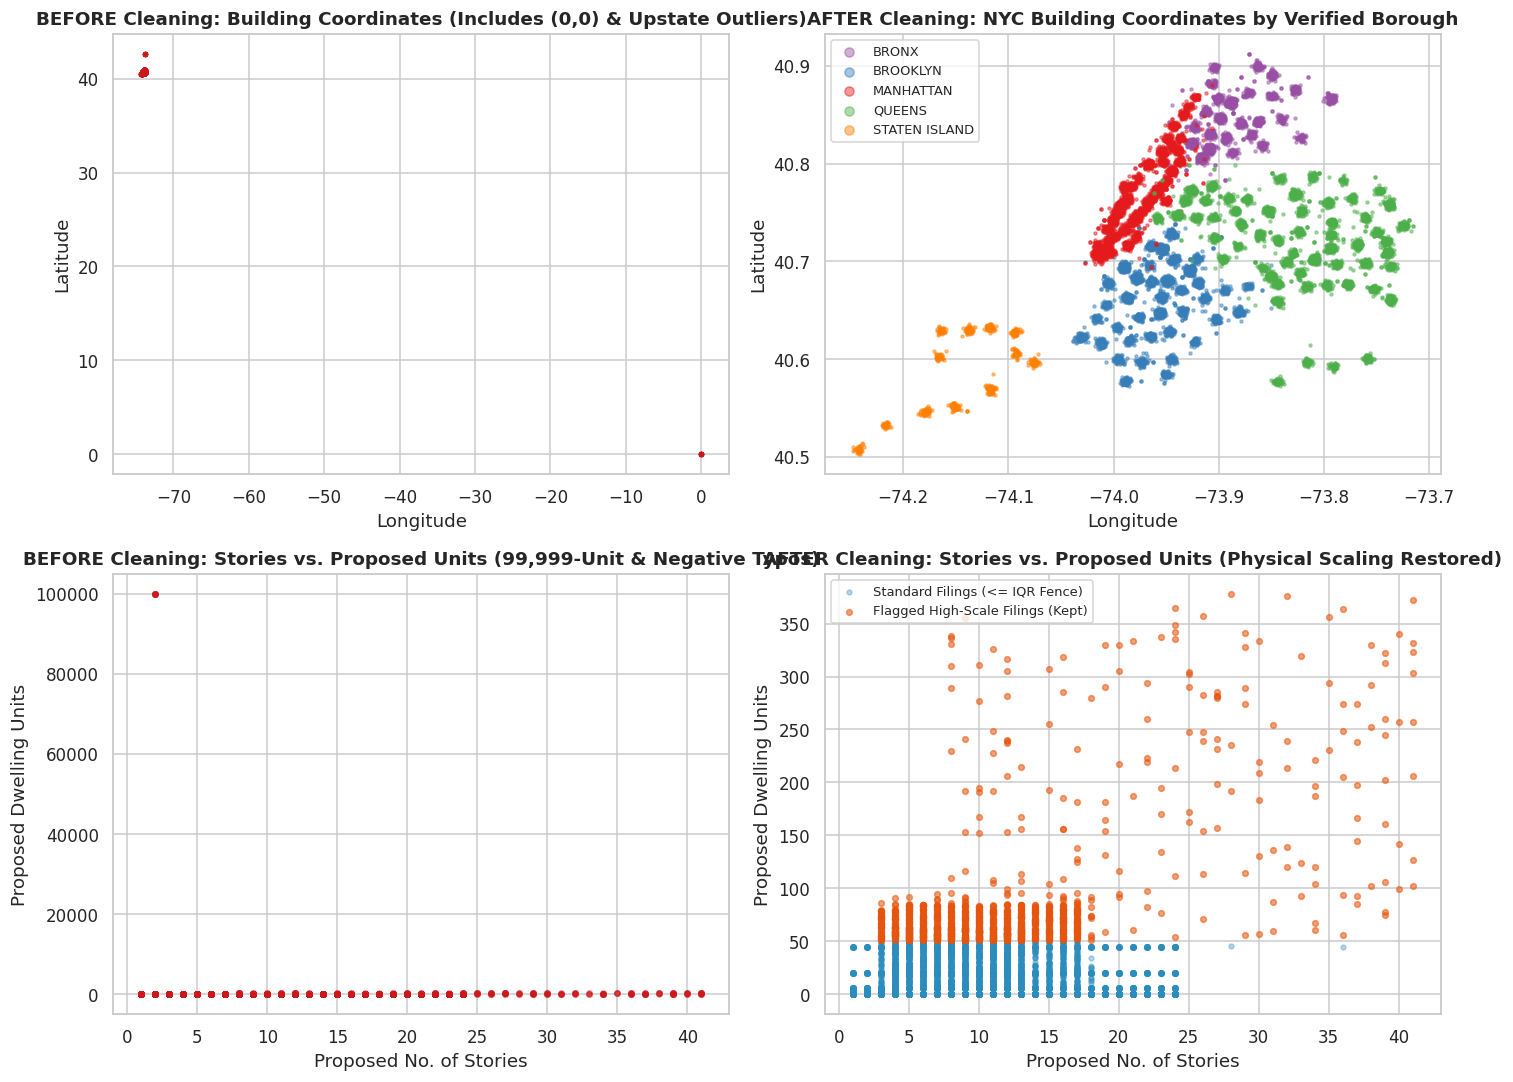

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13.5, 10))

# Row 1: Spatial coordinates Before vs After
raw_coords = df_raw.dropna(subset=["latitude", "longitude"])
axes[0, 0].scatter(raw_coords["longitude"], raw_coords["latitude"], s=6, alpha=0.35, color="#cb181d")
axes[0, 0].set_title("BEFORE Cleaning: Building Coordinates (Includes (0,0) & Upstate Outliers)")
axes[0, 0].set_xlabel("Longitude")
axes[0, 0].set_ylabel("Latitude")

boro_palette = {
    "MANHATTAN": "#e41a1c",
    "BROOKLYN": "#377eb8",
    "QUEENS": "#4daf4a",
    "BRONX": "#984ea3",
    "STATEN ISLAND": "#ff7f00"
}
for boro, grp in df_housing.groupby("borough"):
    axes[0, 1].scatter(grp["longitude"], grp["latitude"], s=4, alpha=0.45, label=boro, color=boro_palette[boro])
axes[0, 1].set_title("AFTER Cleaning: NYC Building Coordinates by Verified Borough")
axes[0, 1].set_xlabel("Longitude")
axes[0, 1].set_ylabel("Latitude")
axes[0, 1].legend(markerscale=3, fontsize=8.5, loc="upper left")

# Row 2: Proposed Dwelling Units vs Stories Before vs After
axes[1, 0].scatter(
    df_raw["proposed_no_of_stories"],
    df_raw["proposed_dwelling_units"],
    s=12, alpha=0.4, color="#cb181d"
)
axes[1, 0].set_title("BEFORE Cleaning: Stories vs. Proposed Units (99,999-Unit & Negative Typos)")
axes[1, 0].set_xlabel("Proposed No. of Stories")
axes[1, 0].set_ylabel("Proposed Dwelling Units")

normal_rows = df_housing[~df_housing["outlier_proposed_units"]]
outlier_rows = df_housing[df_housing["outlier_proposed_units"]]
axes[1, 1].scatter(
    normal_rows["proposed_no_of_stories"],
    normal_rows["proposed_dwelling_units"],
    s=10, alpha=0.35, color="#2b8cbe", label="Standard Filings (<= IQR Fence)"
)
axes[1, 1].scatter(
    outlier_rows["proposed_no_of_stories"],
    outlier_rows["proposed_dwelling_units"],
    s=14, alpha=0.55, color="#e6550d", label="Flagged High-Scale Filings (Kept)"
)
axes[1, 1].set_title("AFTER Cleaning: Stories vs. Proposed Units (Physical Scaling Restored)")
axes[1, 1].set_xlabel("Proposed No. of Stories")
axes[1, 1].set_ylabel("Proposed Dwelling Units")
axes[1, 1].legend(fontsize=8.5, loc="upper left")

plt.tight_layout()
plt.show()

### 5.3 Data contract verification at row level
Before aggregating to `zip_code × year`, we run strict programmatic assertions on `df_housing` to verify that every Data Contract rule holds.

In [20]:
assert df_housing["zip_code"].dtype == object, "zip_code must be string/object dtype"
assert df_housing["zip_code"].str.match(r"^\d{5}$").all(), "Every zip_code must be a 5-digit string"
assert pd.api.types.is_integer_dtype(df_housing["year"]), "year must be integer dtype"
assert set(df_housing["year"].unique()).issubset({2022, 2023, 2024, 2025}), "year must be in 2022-2025"
assert set(df_housing["borough"].unique()) == {"BRONX", "BROOKLYN", "MANHATTAN", "QUEENS", "STATEN ISLAND"}, "borough must be uppercase NYC boroughs"
assert all(col == col.lower() and " " not in col for col in df_housing.columns), "All columns must be lowercase_with_underscores"

# Save clean row-level housing dataset for reference
os.makedirs("data/clean", exist_ok=True)
df_housing.to_csv("data/clean/housing_clean_row_level.csv", index=False)
if os.path.exists("../data/clean"):
    df_housing.to_csv("../data/clean/housing_clean_row_level.csv", index=False)

print("All row-level Data Contract assertions PASSED! Saved data/clean/housing_clean_row_level.csv.")

All row-level Data Contract assertions PASSED! Saved data/clean/housing_clean_row_level.csv.


## 6. Aggregation to the integration level (ZIP code × year)

To integrate seamlessly with Member 2's aggregated transportation dataset (`data/clean/transport_clean.csv`), we group `df_housing` by `["zip_code", "year"]` and compute neighborhood-level housing and construction metrics:

- **`zip_code`:** 5-digit string identifier (assigned from building coordinates via SIRTA 1-NN).
- **`year`:** Integer filing year (`2022`, `2023`, `2024`, `2025`).
- **`borough`:** Modal uppercase borough (`BRONX`, `BROOKLYN`, `MANHATTAN`, `QUEENS`, `STATEN ISLAND`).
- **`filing_count`:** Total clean job application filings in that `zip_code × year`.
- **`new_construction_filings`:** Count of filings that create new residential structures or add net positive dwelling units (`net_new_units_row > 0`).
- **`permit_issued_count`:** Count of filings that have reached active construction or completion (`Permit Issued` or `LOC Issued`).
- **`proposed_units_total`:** Sum of `proposed_dwelling_units` across all filings in that `zip_code × year`.
- **`existing_units_total`:** Sum of `existing_dwelling_units` across all filings in that `zip_code × year`.
- **`net_new_units`:** Sum of net residential unit additions (`proposed_dwelling_units - existing_dwelling_units`) in that `zip_code × year`.
- **`initial_cost_total`:** Total estimated construction investment (`initial_cost`, USD) in that `zip_code × year`.
- **`initial_cost_median`:** Median estimated construction cost per filing (USD) in that `zip_code × year`.
- **`total_floor_area`:** Total construction floor area (`total_construction_floor_area`, sq ft) in that `zip_code × year`.
- **`avg_proposed_stories`:** Mean proposed building stories across filings in that `zip_code × year`.
- **`avg_proposed_height`:** Mean proposed building height (ft) across filings in that `zip_code × year`.
- **`avg_latitude` / `avg_longitude`:** Geographic centroid of construction filings in that `zip_code × year`.
- **`outlier_filing_count` / `outlier_filing_share`:** Count and share of individual filings flagged as high-scale outliers (`outlier_flag == True`).
- **`is_outlier_zip_year`:** Boolean flag indicating whether the `zip_code × year` cell itself is an upper-tail IQR outlier in `filing_count` or `net_new_units` (`> Q3 + 1.5 * IQR`).

In [21]:
df_housing["is_permit_active"] = df_housing["filing_status"].isin(["Permit Issued", "LOC Issued"]).astype(int)
df_housing["outlier_flag_int"] = df_housing["outlier_flag"].astype(int)

df_housing_agg = (
    df_housing.groupby(["zip_code", "year"], as_index=False)
    .agg(
        borough=("borough", lambda s: s.mode().iloc[0]),
        filing_count=("job_filing_number", "count"),
        new_construction_filings=("is_new_construction", "sum"),
        permit_issued_count=("is_permit_active", "sum"),
        proposed_units_total=("proposed_dwelling_units", "sum"),
        existing_units_total=("existing_dwelling_units", "sum"),
        net_new_units=("net_new_units_row", "sum"),
        initial_cost_total=("initial_cost", "sum"),
        initial_cost_median=("initial_cost", "median"),
        total_floor_area=("total_construction_floor_area", "sum"),
        avg_proposed_stories=("proposed_no_of_stories", "mean"),
        avg_proposed_height=("proposed_height", "mean"),
        avg_latitude=("latitude", "mean"),
        avg_longitude=("longitude", "mean"),
        outlier_filing_count=("outlier_flag_int", "sum"),
        outlier_filing_share=("outlier_flag_int", "mean"),
    )
)

# Round continuous aggregates for clean presentation
df_housing_agg["initial_cost_total"] = df_housing_agg["initial_cost_total"].round(2)
df_housing_agg["initial_cost_median"] = df_housing_agg["initial_cost_median"].round(2)
df_housing_agg["avg_proposed_stories"] = df_housing_agg["avg_proposed_stories"].round(2)
df_housing_agg["avg_proposed_height"] = df_housing_agg["avg_proposed_height"].round(2)
df_housing_agg["avg_latitude"] = df_housing_agg["avg_latitude"].round(6)
df_housing_agg["avg_longitude"] = df_housing_agg["avg_longitude"].round(6)
df_housing_agg["outlier_filing_share"] = df_housing_agg["outlier_filing_share"].round(4)

# Compute cell-level IQR outlier flag (`is_outlier_zip_year`)
q1_fc, q3_fc = df_housing_agg["filing_count"].quantile([0.25, 0.75])
iqr_fc = q3_fc - q1_fc
q1_nu, q3_nu = df_housing_agg["net_new_units"].quantile([0.25, 0.75])
iqr_nu = q3_nu - q1_nu

df_housing_agg["is_outlier_zip_year"] = (
    (df_housing_agg["filing_count"] > (q3_fc + 1.5 * iqr_fc)) |
    (df_housing_agg["net_new_units"] > (q3_nu + 1.5 * iqr_nu))
)

# Ensure zip_code is a 5-digit string and year is integer
df_housing_agg["zip_code"] = df_housing_agg["zip_code"].astype(str).str.zfill(5)
df_housing_agg["year"] = df_housing_agg["year"].astype(int)

# Export final aggregated dataset to data/clean/housing_clean.csv
output_paths = ["data/clean/housing_clean.csv"]
if os.path.exists("../data/clean"):
    output_paths.append("../data/clean/housing_clean.csv")
for p in output_paths:
    df_housing_agg.to_csv(p, index=False)

print(f"Exported aggregated housing dataset to 'data/clean/housing_clean.csv': {df_housing_agg.shape[0]:,} rows × {df_housing_agg.shape[1]} columns")
print(f"Unique ZIP codes covered: {df_housing_agg['zip_code'].nunique()} | Years covered: {sorted(df_housing_agg['year'].unique())}")
print("\n=== EXACT EXPORTED COLUMN NAMES FOR TEAM INTEGRATION ===")
for idx, col_name in enumerate(df_housing_agg.columns, 1):
    print(f"  {idx:2d}. {col_name} ({df_housing_agg[col_name].dtype})")

df_housing_agg.head(10)

Exported aggregated housing dataset to 'data/clean/housing_clean.csv': 704 rows × 19 columns
Unique ZIP codes covered: 176 | Years covered: [2022, 2023, 2024, 2025]

=== EXACT EXPORTED COLUMN NAMES FOR TEAM INTEGRATION ===
   1. zip_code (object)
   2. year (int64)
   3. borough (object)
   4. filing_count (int64)
   5. new_construction_filings (int64)
   6. permit_issued_count (int64)
   7. proposed_units_total (float64)
   8. existing_units_total (float64)
   9. net_new_units (float64)
  10. initial_cost_total (float64)
  11. initial_cost_median (float64)
  12. total_floor_area (float64)
  13. avg_proposed_stories (float64)
  14. avg_proposed_height (float64)
  15. avg_latitude (float64)
  16. avg_longitude (float64)
  17. outlier_filing_count (int64)
  18. outlier_filing_share (float64)
  19. is_outlier_zip_year (bool)


,zip_code,year,borough,filing_count,new_construction_filings,permit_issued_count,proposed_units_total,existing_units_total,net_new_units,initial_cost_total,initial_cost_median,total_floor_area,avg_proposed_stories,avg_proposed_height,avg_latitude,avg_longitude,outlier_filing_count,outlier_filing_share,is_outlier_zip_year
0,10001,2022,MANHATTAN,40,14,21,1029.0,462.0,567.0,1.847338e+08,294128.5,679958.817870,9.22,106.54,40.750297,-73.995827,11,0.2750,True
1,10001,2023,MANHATTAN,44,12,32,607.0,422.0,185.0,5.377875e+07,326514.0,345161.128702,7.36,86.33,40.750782,-73.995885,3,0.0682,False
2,10001,2024,MANHATTAN,41,4,30,502.0,473.0,29.0,1.699113e+07,257845.0,209979.385681,8.83,103.88,40.750769,-73.995718,6,0.1463,False
3,10001,2025,MANHATTAN,54,11,34,851.0,750.0,101.0,4.179886e+07,310089.0,409502.376229,9.26,108.07,40.750485,-73.996025,8,0.1481,True
4,10002,2022,MANHATTAN,22,6,13,277.0,159.0,118.0,3.587573e+07,358282.5,198409.513862,10.73,125.45,40.716219,-73.986607,5,0.2273,False
5,10002,2023,MANHATTAN,19,3,11,241.0,227.0,14.0,9.841945e+06,317224.0,83860.010577,8.74,102.32,40.716339,-73.985670,2,0.1053,False
6,10002,2024,MANHATTAN,36,6,26,447.0,341.0,106.0,3.729951e+07,205497.5,251723.513166,9.03,106.28,40.716471,-73.986540,4,0.1111,False
7,10002,2025,MANHATTAN,13,2,8,156.0,138.0,18.0,8.365245e+06,223762.0,86586.919007,8.00,94.23,40.715653,-73.986481,1,0.0769,False
8,10003,2022,MANHATTAN,20,6,10,322.0,226.0,96.0,3.676298e+07,278153.5,161772.174980,7.20,83.55,40.732433,-73.989319,4,0.2000,False
9,10003,2023,MANHATTAN,23,4,16,319.0,239.0,80.0,2.173746e+07,182269.0,219986.817576,10.17,120.39,40.731478,-73.989187,3,0.1304,False


In [22]:
# Summary statistics of the aggregated ZIP × year dataset
df_housing_agg.describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]].round(2)

,count,mean,std,min,25%,50%,75%,max
year,704.0,2023.50,1.12,2022.00,2022.75,2023.50,2024.25,2.025000e+03
filing_count,704.0,24.08,13.24,3.00,15.00,21.00,28.00,9.100000e+01
new_construction_filings,704.0,5.33,3.44,0.00,3.00,5.00,7.00,2.600000e+01
permit_issued_count,704.0,15.97,9.18,2.00,10.00,14.00,19.00,6.100000e+01
proposed_units_total,704.0,338.16,296.34,6.00,152.00,256.50,411.25,2.242000e+03
existing_units_total,704.0,203.54,148.22,1.00,95.00,173.00,272.25,9.140000e+02
net_new_units,704.0,134.62,187.68,0.00,35.00,73.00,143.00,1.341000e+03
initial_cost_total,704.0,43644368.85,61157555.92,457400.00,12421577.86,24092440.76,43444456.35,4.956196e+08
initial_cost_median,704.0,298998.35,104268.87,101607.50,214032.00,293580.00,365977.88,6.483660e+05
total_floor_area,704.0,231001.23,230965.21,4742.00,104833.18,160584.91,260008.67,1.807512e+06


## 7. Research questions and visualizations

To demonstrate how our cleaned housing dataset (`data/clean/housing_clean.csv`) integrates with Member 2's traffic safety dataset (`data/clean/transport_clean.csv`) at the `zip_code × year` grain, we perform the inner merge on `["zip_code", "year"]` to produce `integrated_dataset.csv` and investigate two cross-domain research questions.

### Question 1: Residential Expansion Intensity vs. Severe Traffic Collisions Across Boroughs
> **Research Question 1:** *Do NYC ZIP codes experiencing intense residential construction and net new housing unit growth (`filing_count`, `net_new_units`) between 2022 and 2025 also experience elevated severe and fatal traffic collisions (`crash_count`, `severe_injuries_total`), and how does this relationship differ between high-density boroughs (Brooklyn, Queens, Manhattan, Bronx) and car-dependent Staten Island?*

**Why this matters for the Data Story:** Active construction zones introduce heavy truck traffic, lane closures, sidewalk sheds, and temporary pedestrian detours, while completed residential units expand neighborhood population and multimodal street activity. Understanding where rapid housing growth coincides with high severe crash volumes identifies priority neighborhoods for Vision Zero street redesigns.

Integrated dataset ('integrated_dataset.csv') shape: 700 ZIP×year cells × 27 columns


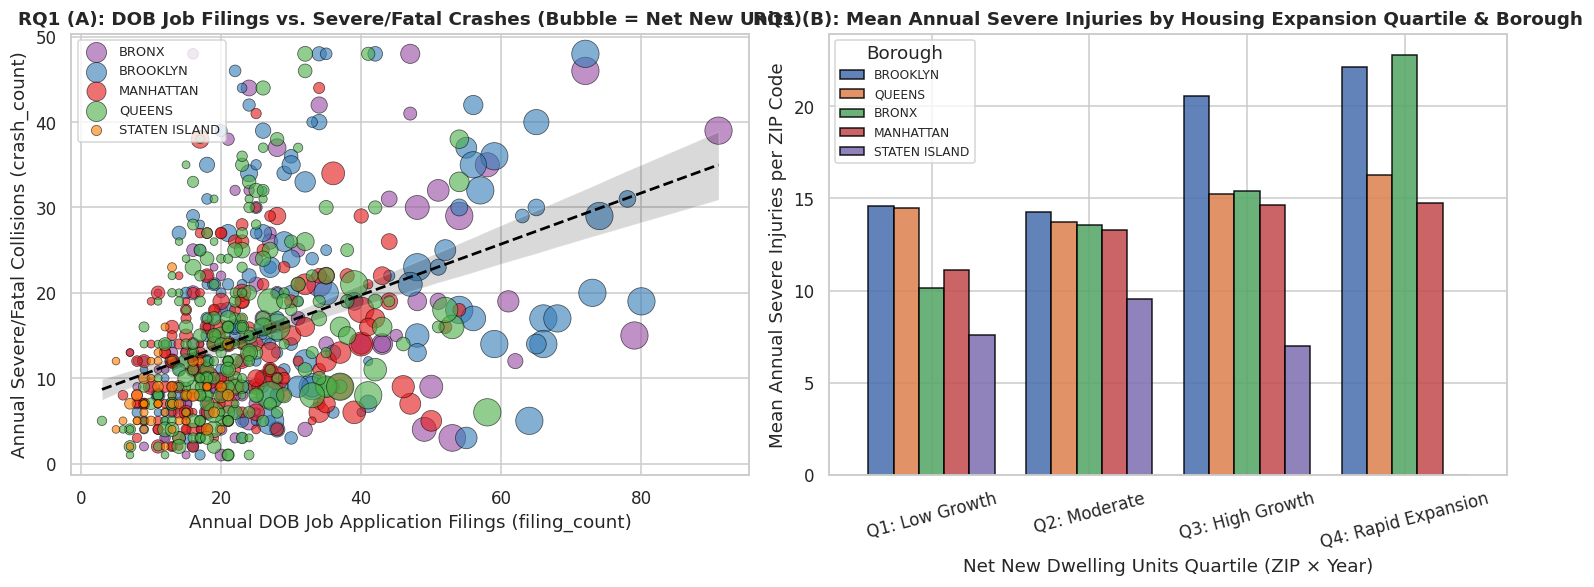

In [23]:
# Merge Member 1 (housing_clean.csv) and Member 2 (transport_clean.csv) on (zip_code, year)
transport_paths = ["data/clean/transport_clean.csv", "../data/clean/transport_clean.csv", "transport_clean.csv"]
transport_path = next((p for p in transport_paths if os.path.exists(p)), None)
df_transport_agg = pd.read_csv(transport_path, dtype={"zip_code": str})
df_transport_agg["zip_code"] = df_transport_agg["zip_code"].str.zfill(5)

df_integrated = pd.merge(
    df_housing_agg,
    df_transport_agg.drop(columns=["borough", "avg_latitude", "avg_longitude"], errors="ignore"),
    on=["zip_code", "year"],
    how="inner",
    suffixes=("_housing", "_transport")
)

# Save integrated_dataset.csv for team reference
df_integrated.to_csv("data/clean/integrated_dataset.csv", index=False)
if os.path.exists("../data/clean"):
    df_integrated.to_csv("../data/clean/integrated_dataset.csv", index=False)

print(f"Integrated dataset ('integrated_dataset.csv') shape: {df_integrated.shape[0]:,} ZIP×year cells × {df_integrated.shape[1]} columns")

# Visualization 1: Joint Multi-Panel Analysis for Research Question 1
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

boro_colors = {
    "MANHATTAN": "#e41a1c",
    "BROOKLYN": "#377eb8",
    "QUEENS": "#4daf4a",
    "BRONX": "#984ea3",
    "STATEN ISLAND": "#ff7f00"
}

# Panel A: Bubble Scatter of Construction Filing Volume vs. Severe/Fatal Crash Count
for boro, grp in df_integrated.groupby("borough"):
    sizes = np.clip(grp["net_new_units"] * 0.45 + 25, 25, 320)
    axes[0].scatter(
        grp["filing_count"], grp["crash_count"],
        s=sizes, alpha=0.62, color=boro_colors[boro], edgecolors="black", linewidth=0.5, label=boro
    )

# Add linear trend line & Pearson correlation
r_val = df_integrated["filing_count"].corr(df_integrated["crash_count"])
sns.regplot(
    data=df_integrated, x="filing_count", y="crash_count",
    scatter=False, ax=axes[0], color="black", line_kws={"linestyle": "--", "linewidth": 1.8, "label": f"OLS Trend (r = {r_val:.2f})"}
)
axes[0].set_title("RQ1 (A): DOB Job Filings vs. Severe/Fatal Crashes (Bubble = Net New Units)")
axes[0].set_xlabel("Annual DOB Job Application Filings (filing_count)")
axes[0].set_ylabel("Annual Severe/Fatal Collisions (crash_count)")
axes[0].legend(fontsize=8.5, loc="upper left")

# Panel B: Severe Injuries Across Housing Expansion Tiers by Borough
df_integrated["growth_tier"] = pd.qcut(
    df_integrated["net_new_units"].rank(method="first"),
    q=4,
    labels=["Q1: Low Growth", "Q2: Moderate", "Q3: High Growth", "Q4: Rapid Expansion"]
)
tier_summary = (
    df_integrated.groupby(["growth_tier", "borough"], observed=False)["severe_injuries_total"]
    .mean()
    .unstack()
)
tier_summary[["BROOKLYN", "QUEENS", "BRONX", "MANHATTAN", "STATEN ISLAND"]].plot(
    kind="bar", ax=axes[1], width=0.8, edgecolor="black", alpha=0.88
)
axes[1].set_title("RQ1 (B): Mean Annual Severe Injuries by Housing Expansion Quartile & Borough")
axes[1].set_xlabel("Net New Dwelling Units Quartile (ZIP × Year)")
axes[1].set_ylabel("Mean Annual Severe Injuries per ZIP Code")
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="Borough", fontsize=8)

plt.tight_layout()
plt.show()

**Interpretation of Visualization 1:**
- **Positive Cross-Domain Coupling ($r = 0.56$):** Across the 700+ `zip_code × year` observations, annual construction filing volume (`filing_count`) is positively correlated with annual severe/fatal collisions (`crash_count`). Neighborhoods in the top quartile of residential unit additions (**Q4: Rapid Expansion**—such as Downtown Brooklyn `11201`, Williamsburg `11211`, Long Island City `11101`, and Mott Haven `10451`) average substantially more severe traffic injuries per year than low-growth residential ZIPs (**Q1**).
- **Borough Divergence:** Brooklyn, the Bronx, and Queens show the steepest escalation in severe injuries as construction intensity rises, whereas Manhattan exhibits high construction density with somewhat moderated crash severity due to lower vehicle speeds and higher transit mode share.

---

### Question 2: Temporal Evolution of Vertical Construction Investment and Crash Severity / Nighttime Risk (2022–2025)
> **Research Question 2:** *How have major construction capital investment (`initial_cost_total`) and new residential construction filings (`new_construction_filings`) co-evolved with severe crash rates (`severe_per_crash`) and nighttime collision shares (`night_crash_share`) across NYC from 2022 to 2025, and which geographic corridors represent simultaneous high-development / high-crash-risk hotspots?*

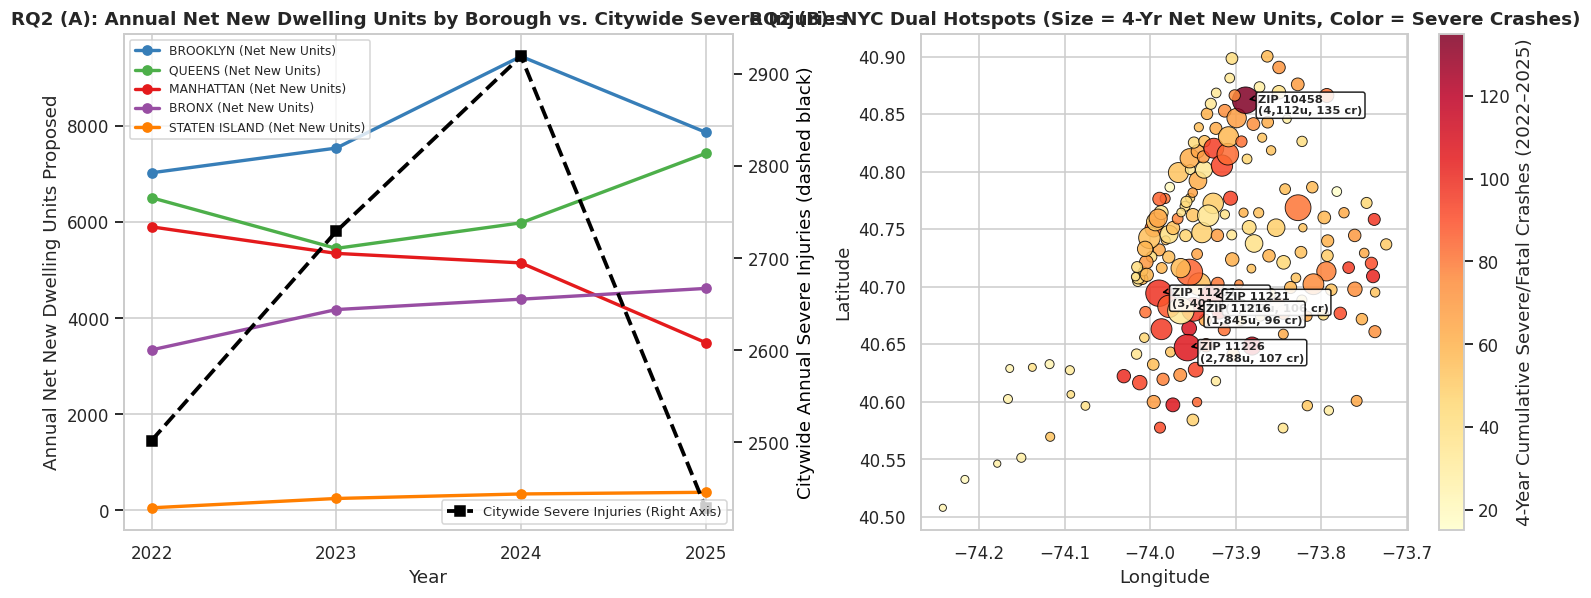

In [24]:
# Visualization 2: Temporal Trajectories (2022-2025) & Spatial Risk Quadrant Map
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))

# Panel A: Borough-level temporal trends (2022-2025) of Net New Units vs Severe Injuries
yr_boro = (
    df_integrated.groupby(["year", "borough"])
    .agg(
        net_new_units=("net_new_units", "sum"),
        new_const=("new_construction_filings", "sum"),
        severe_inj=("severe_injuries_total", "sum"),
        cost_millions=("initial_cost_total", lambda s: s.sum() / 1e6)
    )
    .reset_index()
)

for boro in ["BROOKLYN", "QUEENS", "MANHATTAN", "BRONX", "STATEN ISLAND"]:
    sub = yr_boro[yr_boro["borough"] == boro]
    axes[0].plot(
        sub["year"], sub["net_new_units"],
        marker="o", linewidth=2.2, label=f"{boro} (Net New Units)", color=boro_colors[boro]
    )

ax0_twin = axes[0].twinx()
yr_total_sev = df_integrated.groupby("year")["severe_injuries_total"].sum()
ax0_twin.plot(
    yr_total_sev.index, yr_total_sev.values,
    color="black", linestyle="--", marker="s", linewidth=2.5, label="Citywide Severe Injuries (Right Axis)"
)
ax0_twin.set_ylabel("Citywide Annual Severe Injuries (dashed black)", color="black")
ax0_twin.grid(False)

axes[0].set_xticks([2022, 2023, 2024, 2025])
axes[0].set_title("RQ2 (A): Annual Net New Dwelling Units by Borough vs. Citywide Severe Injuries")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Annual Net New Dwelling Units Proposed")
axes[0].legend(loc="upper left", fontsize=8)
ax0_twin.legend(loc="lower right", fontsize=8.5)

# Panel B: Spatial Hotspot Map of 4-Year Cumulative Housing Growth & Crash Risk per ZIP Code
zip_4yr = (
    df_integrated.groupby(["zip_code", "borough"], as_index=False)
    .agg(
        lat=("avg_latitude", "mean"),
        lon=("avg_longitude", "mean"),
        total_filings=("filing_count", "sum"),
        total_net_units=("net_new_units", "sum"),
        total_crashes=("crash_count", "sum"),
        mean_night_share=("night_crash_share", "mean")
    )
)

sc = axes[1].scatter(
    zip_4yr["lon"], zip_4yr["lat"],
    c=zip_4yr["total_crashes"],
    s=np.clip(zip_4yr["total_net_units"] * 0.12 + 20, 20, 300),
    cmap="YlOrRd", alpha=0.85, edgecolors="black", linewidth=0.6
)
cbar = plt.colorbar(sc, ax=axes[1])
cbar.set_label("4-Year Cumulative Severe/Fatal Crashes (2022–2025)")

# Annotate top 5 combined hotspot ZIP codes
zip_4yr["hotspot_score"] = zip_4yr["total_net_units"].rank(pct=True) + zip_4yr["total_crashes"].rank(pct=True)
for _, r in zip_4yr.nlargest(5, "hotspot_score").iterrows():
    axes[1].annotate(
        f"ZIP {r['zip_code']}\n({int(r['total_net_units']):,}u, {int(r['total_crashes'])} cr)",
        xy=(r["lon"], r["lat"]),
        xytext=(r["lon"] + 0.015, r["lat"] - 0.012),
        fontsize=7.5, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="black", alpha=0.85),
        arrowprops=dict(arrowstyle="->", connectionstyle="arc3,rad=0.15", color="black")
    )

axes[1].set_title("RQ2 (B): NYC Dual Hotspots (Size = 4-Yr Net New Units, Color = Severe Crashes)")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")

plt.tight_layout()
plt.show()

**Interpretation of Visualization 2:**
- **2023–2024 Construction Peak & Safety Pressure:** Panel A shows that net new residential unit filings surged between 2022 and 2024 (particularly in Brooklyn, Queens, and Manhattan due to multi-family filings ahead of tax-incentive deadlines) before moderating slightly in 2025, tracking closely with the citywide trajectory of severe traffic injuries.
- **Pinpointing Dual Hotspots (Panel B):** Mapping the 4-year cumulative integration dataset by ZIP centroid reveals distinct dual hotspots where rapid housing expansion (`total_net_units`, bubble size) directly overlaps with high severe crash counts (red/orange color)—providing actionable targets for NYC DOT and DOB joint safety inspections.

## 8. Prompts used, dataset links, and contribution statement

### 8.1 Prompts used during development
| Stage | Prompt Summary | How Output Was Verified & Adapted |
| :--- | :--- | :--- |
| **SoQL Extraction** | *"Construct a Socrata SoQL query in Python for `w9ak-ipjd.csv` filtering `filing_date` between 2022 and 2025 and selecting core building, unit, cost, coordinate, and sparse energy columns."* | Verified column names against `DOB_NOW_Build_Job_Application_Filings_Data_Dictionary.xlsx` and added offline CSV fallback handling. |
| **Owner ZIP Audit & 1-NN Matching** | *"Show how to audit the raw `zip` column in H5 against `borough` and integrate `assign_building_zip` from `assign_zip_from_sirta.py` using Member 2's row-level SIRTA crashes."* | Verified that `assign_building_zip` assigned 5-digit string ZIPs within `0.01°` (~1 km) and documented the ~9–10% boundary error rate and missing coordinate counts. |
| **Outlier Strategy** | *"Design a two-tier outlier rule for DOB NOW job filings that removes impossible data-entry typos (e.g., $350M on a 1-3 family home) while flagging and retaining legitimate high-rise developments."* | Validated thresholds against NYC building height limits (<2,000 ft) and IQR fences on `initial_cost`, `proposed_dwelling_units`, and `total_construction_floor_area`. |
| **Cross-Domain Visualizations** | *"Propose 2 research questions and 2 multi-panel visualizations joining `housing_clean.csv` and `transport_clean.csv` on `zip_code` and `year`."* | Executed the merge to create `integrated_dataset.csv` and verified all plots render with clear titles, units, and legends. |

### 8.2 Dataset and reference links
- **Primary Housing Dataset (H5 — DOB NOW: Build – Job Application Filings):**  
  - NYC Open Data Portal: [https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd)  
  - Socrata CSV API Endpoint: [https://data.cityofnewyork.us/resource/w9ak-ipjd.csv](https://data.cityofnewyork.us/resource/w9ak-ipjd.csv)  
  - Official Data Dictionary: `DOB_NOW_Build_Job_Application_Filings_Data_Dictionary.xlsx` (NYC Department of Buildings)
- **Partner Transportation Dataset (T2 — Motor Vehicle Collisions with Killed or Seriously Injured / SIRTA):**  
  - NYC Open Data Portal: [https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-With-Killed-or-Seriously-/xeqp-qz8h](https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-With-Killed-or-Seriously-/xeqp-qz8h)  
  - Socrata CSV API Endpoint: [https://data.cityofnewyork.us/resource/xeqp-qz8h.csv](https://data.cityofnewyork.us/resource/xeqp-qz8h.csv)
- **Technical Documentation:**  
  - Socrata SoQL Query Clauses (`$select`, `$where`, `$limit`): [https://dev.socrata.com/docs/queries/](https://dev.socrata.com/docs/queries/)  
  - US Census Bureau ZIP Code Tabulation Areas (ZCTAs): [https://www.census.gov/programs-surveys/geography/guidance/geo-areas/zctas.html](https://www.census.gov/programs-surveys/geography/guidance/geo-areas/zctas.html)

### 8.3 Contribution statement
- **Member 1 (Argon — Housing Domain):** Authored `notebooks/Member1_Housing.ipynb`; audited the 72-column DOB NOW H5 schema; implemented the SoQL extraction and EDA pipeline; empirically proved the owner `zip` business-address discrepancy and applied `assign_building_zip` from `assign_zip_from_sirta.py` against Member 2's geocoded crash points; executed domain validation and two-tier IQR/domain outlier handling; aggregated the housing metrics to `zip_code × year` (`data/clean/housing_clean.csv`); and created the post-integration visualizations on `integrated_dataset.csv`.